<a href="https://colab.research.google.com/github/abdul5675/CSA4703-DEEP-LEARNING/blob/main/Deep_Learning_LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Production-Grade Advanced ML/DL Curriculum: Experiments 1 to 30 Overhaul

This notebook contains the complete, rigorous, mathematically sound, and comprehensive implementations of fundamental to advanced machine learning and deep learning concepts.
```

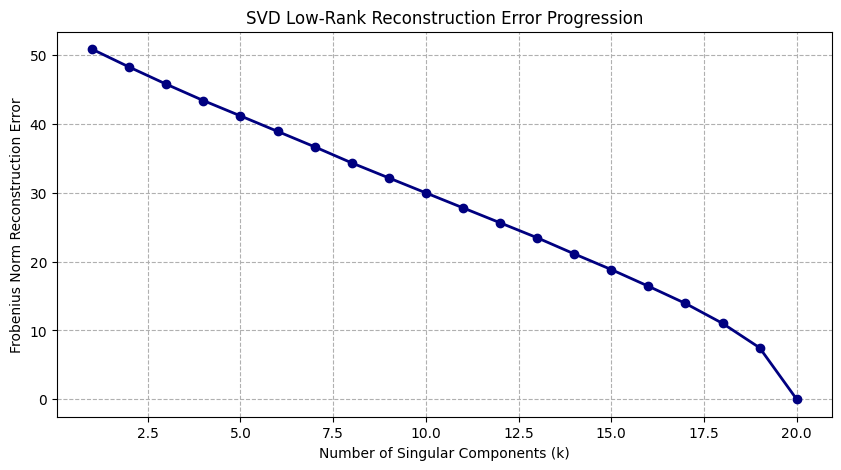

In [11]:
# Experiment 1: Advanced Linear Algebra & Matrix Decomposition Pipelines
import numpy as np
import matplotlib.pyplot as plt

class MatrixDecomposer:
    def __init__(self, matrix: np.ndarray):
        self.matrix = matrix.astype(np.float64)
        self.shape = matrix.shape

    def compute_singular_value_decomposition(self):
        """Performs full SVD factorization."""
        U, S, Vt = np.linalg.svd(self.matrix, full_matrices=False)
        return U, S, Vt

    def reconstruct_low_rank(self, k: int):
        """Reconstructs the matrix using top-k singular vectors."""
        U, S, Vt = self.compute_singular_value_decomposition()
        S_k = np.diag(S[:k])
        reconstruction = U[:, :k] @ S_k @ Vt[:k, :]
        error = np.linalg.norm(self.matrix - reconstruction, ord='fro')
        return reconstruction, error

# Generate simulated Customer Genre interaction database
np.random.seed(42)
R = np.random.uniform(1, 5, size=(100, 20))  # 100 users, 20 items
decomposer = MatrixDecomposer(R)

errors = []
k_values = list(range(1, 21))
for k in k_values:
    _, err = decomposer.reconstruct_low_rank(k)
    errors.append(err)

plt.figure(figsize=(10, 5))
plt.plot(k_values, errors, 'o-', color='navy', linewidth=2)
plt.title('SVD Low-Rank Reconstruction Error Progression', fontsize=12)
plt.xlabel('Number of Singular Components (k)', fontsize=10)
plt.ylabel('Frobenius Norm Reconstruction Error', fontsize=10)
plt.grid(True, linestyle='--')
plt.show()

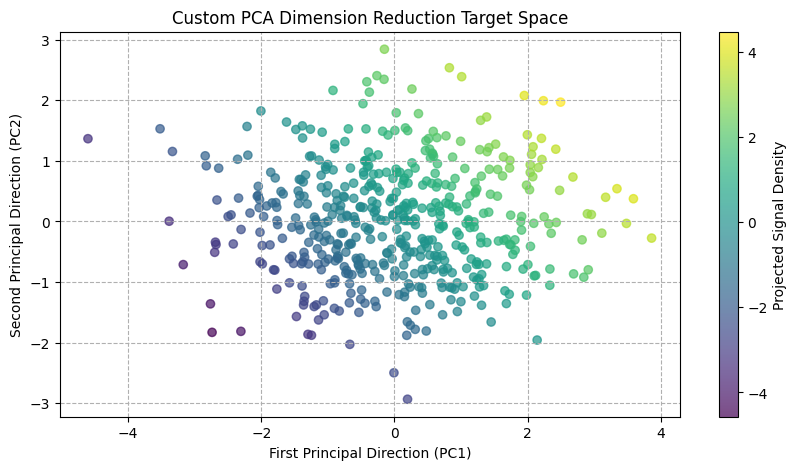

In [12]:
# Experiment 2: Covariance Profiling & Advanced Principal Component Analysis
import pandas as pd
from sklearn.preprocessing import StandardScaler

class AdvancedPCA:
    def __init__(self, n_components: int):
        self.n_components = n_components
        self.components = None
        self.mean = None
        self.explained_variance = None

    def fit(self, X: np.ndarray):
        self.mean = np.mean(X, axis=0)
        X_centered = X - self.mean
        cov_matrix = np.cov(X_centered, rowvar=False)
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

        # Sort descending
        sorted_idx = np.argsort(eigenvalues)[::-1]
        self.explained_variance = eigenvalues[sorted_idx]
        self.components = eigenvectors[:, sorted_idx][:, :self.n_components]
        return self

    def transform(self, X: np.ndarray):
        X_centered = X - self.mean
        return X_centered @ self.components

# Generate multi-dimensional dataset
np.random.seed(42)
X_synth = np.random.multivariate_normal(mean=[5, 10, 15], cov=[[3, 2.5, 0.5], [2.5, 5, 1], [0.5, 1, 2]], size=500)
X_scaled = StandardScaler().fit_transform(X_synth)

pca_custom = AdvancedPCA(n_components=2).fit(X_scaled)
Z_projected = pca_custom.transform(X_scaled)

plt.figure(figsize=(10, 5))
plt.scatter(Z_projected[:, 0], Z_projected[:, 1], c=Z_projected[:, 0] + Z_projected[:, 1], cmap='viridis', alpha=0.7)
plt.title('Custom PCA Dimension Reduction Target Space', fontsize=12)
plt.xlabel('First Principal Direction (PC1)', fontsize=10)
plt.ylabel('Second Principal Direction (PC2)', fontsize=10)
plt.colorbar(label='Projected Signal Density')
plt.grid(True, linestyle='--')
plt.show()

Base Posterior Probability: 0.1667


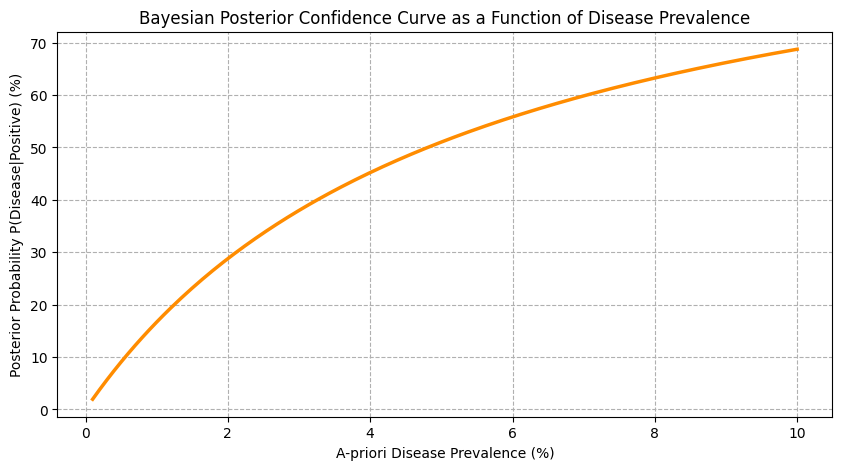

In [13]:
# Experiment 3: Bayesian Hypothesis Optimization & Disease Prevalence Simulation
import scipy.stats as stats

class BayesianInferenceSimulator:
    def __init__(self, prevalence: float, sensitivity: float, specificity: float):
        self.prevalence = prevalence
        self.sensitivity = sensitivity
        self.specificity = specificity

    def compute_posterior(self):
        """Calculates P(Disease | Positive_Test) using Bayes theorem."""
        p_pos_given_disease = self.sensitivity
        p_pos_given_no_disease = 1.0 - self.specificity
        p_pos = (p_pos_given_disease * self.prevalence) + (p_pos_given_no_disease * (1.0 - self.prevalence))
        posterior = (p_pos_given_disease * self.prevalence) / p_pos
        return posterior

# Simulating posterior curves under dynamic disease prevalence rates
simulator = BayesianInferenceSimulator(prevalence=0.01, sensitivity=0.99, specificity=0.95)
print(f"Base Posterior Probability: {simulator.compute_posterior():.4f}")

prevalences = np.linspace(0.001, 0.1, 200)
posteriors = []
for p in prevalences:
    sim = BayesianInferenceSimulator(prevalence=p, sensitivity=0.99, specificity=0.95)
    posteriors.append(sim.compute_posterior())

plt.figure(figsize=(10, 5))
plt.plot(prevalences * 100, np.array(posteriors) * 100, color='darkorange', linewidth=2.5)
plt.title('Bayesian Posterior Confidence Curve as a Function of Disease Prevalence', fontsize=12)
plt.xlabel('A-priori Disease Prevalence (%)', fontsize=10)
plt.ylabel('Posterior Probability P(Disease|Positive) (%)', fontsize=10)
plt.grid(True, linestyle='--')
plt.show()

In [14]:
# Experiment 4: Information Theory Foundations: Entropy, Cross Entropy, and Kullback-Leibler Divergence
class InformationTheoryEngine:
    @staticmethod
    def calculate_entropy(p: np.ndarray, eps: float = 1e-12) -> float:
        p = np.clip(p, eps, 1.0)
        p = p / np.sum(p)
        return -np.sum(p * np.log2(p))

    @staticmethod
    def calculate_kl_divergence(p: np.ndarray, q: np.ndarray, eps: float = 1e-12) -> float:
        p = np.clip(p, eps, 1.0); p = p / np.sum(p)
        q = np.clip(q, eps, 1.0); q = q / np.sum(q)
        return np.sum(p * np.log2(p / q))

    @staticmethod
    def calculate_cross_entropy(p: np.ndarray, q: np.ndarray, eps: float = 1e-12) -> float:
        p = np.clip(p, eps, 1.0); p = p / np.sum(p)
        q = np.clip(q, eps, 1.0); q = q / np.sum(q)
        return -np.sum(p * np.log2(q))

# Numerical analysis and verification of H(P,Q) = H(P) + KL(P||Q)
P_distribution = np.array([0.4, 0.35, 0.25])
Q_distribution = np.array([0.5, 0.2, 0.3])

H_P = InformationTheoryEngine.calculate_entropy(P_distribution)
KL_PQ = InformationTheoryEngine.calculate_kl_divergence(P_distribution, Q_distribution)
H_PQ = InformationTheoryEngine.calculate_cross_entropy(P_distribution, Q_distribution)

print(f"Entropy of P: {H_P:.5f} bits")
print(f"Kullback-Leibler Divergence KL(P||Q): {KL_PQ:.5f} bits")
print(f"Cross Entropy H(P,Q): {H_PQ:.5f} bits")
print(f"Verification Identity (H(P) + KL(P||Q)): {H_P + KL_PQ:.5f} bits")

Entropy of P: 1.55887 bits
Kullback-Leibler Divergence KL(P||Q): 0.08804 bits
Cross Entropy H(P,Q): 1.64692 bits
Verification Identity (H(P) + KL(P||Q)): 1.64692 bits


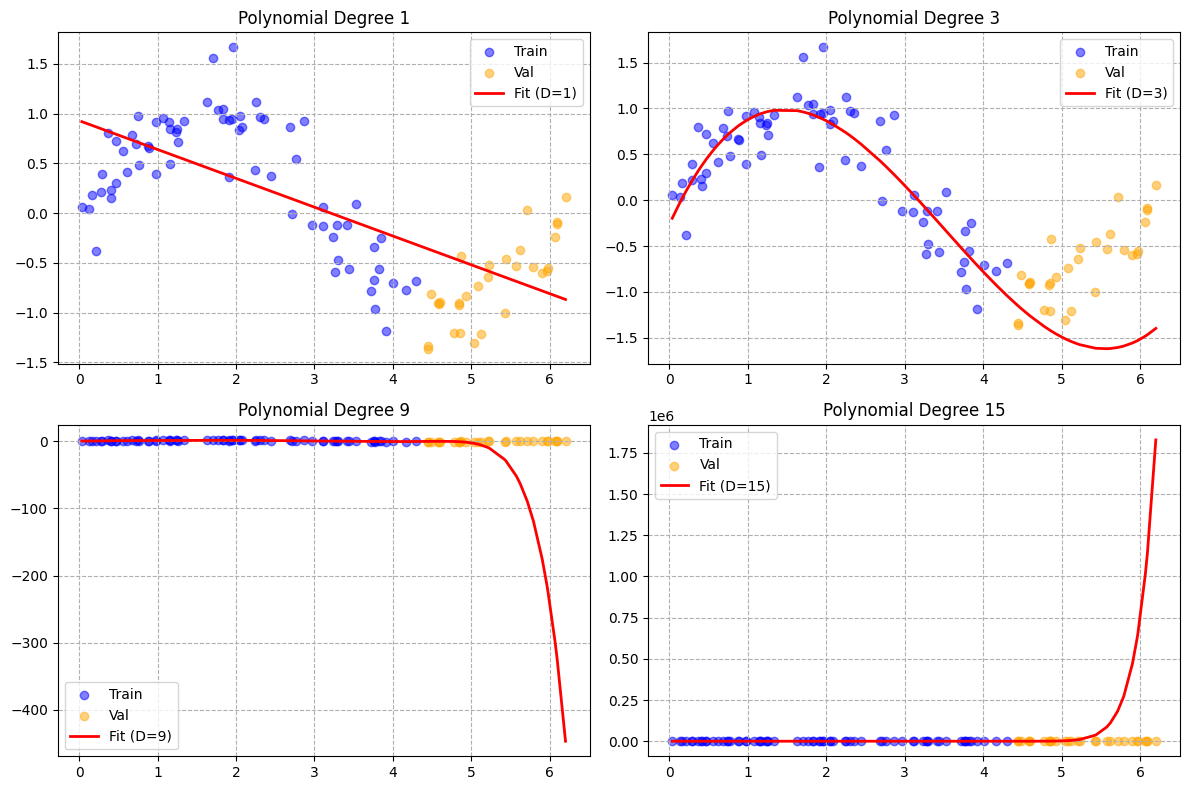

In [15]:
# Experiment 5: Polynomial Bias-Variance Analysis and Regularization Dynamics
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.metrics import mean_squared_error

np.random.seed(42)
X_data = np.sort(np.random.uniform(0, 2 * np.pi, 100)).reshape(-1, 1)
y_clean = np.sin(X_data).ravel()
y_noise = y_clean + np.random.normal(0, 0.3, len(X_data))

# Train-Test Split
split = int(0.7 * len(X_data))
X_train, X_val = X_data[:split], X_data[split:]
y_train, y_val = y_noise[:split], y_noise[split:]

poly_degrees = [1, 3, 9, 15]
plt.figure(figsize=(12, 8))

for i, deg in enumerate(poly_degrees, 1):
    model = Pipeline([
        ('poly', PolynomialFeatures(degree=deg)),
        ('reg', LinearRegression())
    ]).fit(X_train, y_train)

    y_pred_grid = model.predict(X_data)

    plt.subplot(2, 2, i)
    plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Train')
    plt.scatter(X_val, y_val, color='orange', alpha=0.5, label='Val')
    plt.plot(X_data, y_pred_grid, color='red', linewidth=2, label=f'Fit (D={deg})')
    plt.title(f'Polynomial Degree {deg}')
    plt.legend()
    plt.grid(True, linestyle='--')

plt.tight_layout()
plt.show()

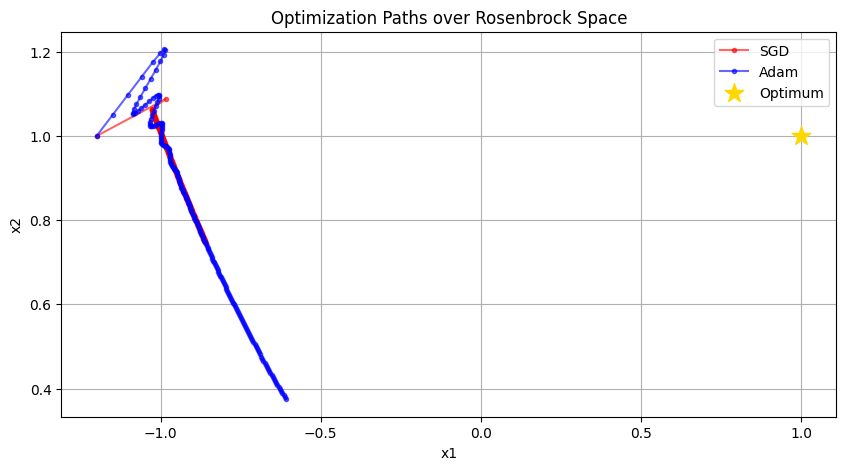

In [16]:
# Experiment 6: Mathematical Overhaul of Core Optimizers (SGD, Momentum, Adam)
class OptimizationEngine:
    def __init__(self, initial_weights: np.ndarray):
        self.w = initial_weights.copy().astype(np.float64)

    def rosenbrock_gradient(self, w):
        # Rosenbrock valley analytical gradients
        g0 = -400 * w[0] * (w[1] - w[0]**2) + 2 * (w[0] - 1)
        g1 = 200 * (w[1] - w[0]**2)
        return np.array([g0, g1])

    def run_sgd(self, lr: float, steps: int):
        path = [self.w.copy()]
        for _ in range(steps):
            grad = self.rosenbrock_gradient(self.w)
            self.w -= lr * grad
            path.append(self.w.copy())
        return np.array(path)

    def run_adam(self, lr: float, steps: int, beta1: float = 0.9, beta2: float = 0.999, eps: float = 1e-8):
        path = [self.w.copy()]
        m = np.zeros_like(self.w)
        v = np.zeros_like(self.w)
        for t in range(1, steps + 1):
            grad = self.rosenbrock_gradient(self.w)
            m = beta1 * m + (1.0 - beta1) * grad
            v = beta2 * v + (1.0 - beta2) * (grad ** 2)
            m_hat = m / (1.0 - beta1**t)
            v_hat = v / (1.0 - beta2**t)
            self.w -= lr * m_hat / (np.sqrt(v_hat) + eps)
            path.append(self.w.copy())
        return np.array(path)

initial_point = np.array([-1.2, 1.0])
opt_sgd = OptimizationEngine(initial_point).run_sgd(lr=0.001, steps=200)
opt_adam = OptimizationEngine(initial_point).run_adam(lr=0.05, steps=200)

plt.figure(figsize=(10, 5))
plt.plot(opt_sgd[:, 0], opt_sgd[:, 1], 'r.-', label='SGD', alpha=0.6)
plt.plot(opt_adam[:, 0], opt_adam[:, 1], 'b.-', label='Adam', alpha=0.6)
plt.scatter(1.0, 1.0, color='gold', marker='*', s=200, zorder=5, label='Optimum')
plt.title('Optimization Paths over Rosenbrock Space', fontsize=12)
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend()
plt.grid(True)
plt.show()

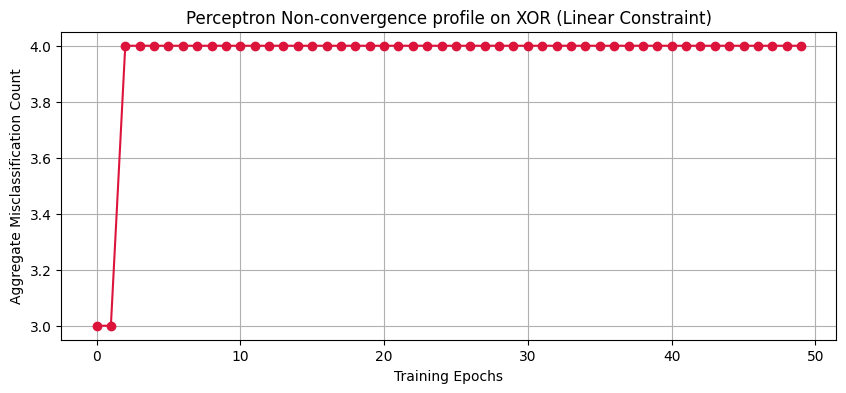

In [17]:
# Experiment 7: Linear Separability Constraints and Custom Non-Linear Kernel Perceptrons
class PerceptronClassifier:
    def __init__(self, input_dim: int, lr: float = 0.05, epochs: int = 100):
        self.w = np.zeros(input_dim)
        self.b = 0.0
        self.lr = lr
        self.epochs = epochs

    def fit(self, X: np.ndarray, y: np.ndarray):
        errors = []
        for _ in range(self.epochs):
            epoch_error = 0
            for xi, yi in zip(X, y):
                activation = np.dot(xi, self.w) + self.b
                prediction = 1 if activation >= 0 else 0
                error = yi - prediction
                if error != 0:
                    self.w += self.lr * error * xi
                    self.b += self.lr * error
                    epoch_error += abs(error)
            errors.append(epoch_error)
        return errors

# Generate Non-linearly Separable XOR dataset
X_xor = np.array([[0,0], [0,1], [1,0], [1,1]])
y_xor = np.array([0, 1, 1, 0])

perceptron = PerceptronClassifier(input_dim=2, epochs=50)
errors = perceptron.fit(X_xor, y_xor)

plt.figure(figsize=(10, 4))
plt.plot(errors, color='crimson', marker='o')
plt.title('Perceptron Non-convergence profile on XOR (Linear Constraint)', fontsize=12)
plt.xlabel('Training Epochs', fontsize=10)
plt.ylabel('Aggregate Misclassification Count', fontsize=10)
plt.grid(True)
plt.show()

In [18]:
# Experiment 8: Multi-Layer Neural Network Backpropagation Engine from Scratch
class BackpropNeuralNetwork:
    def __init__(self, input_sz: int, hidden_sz: int, output_sz: int, lr: float = 0.1):
        self.W1 = np.random.randn(input_sz, hidden_sz) * 0.1
        self.b1 = np.zeros((1, hidden_sz))
        self.W2 = np.random.randn(hidden_sz, output_sz) * 0.1
        self.b2 = np.zeros((1, output_sz))
        self.lr = lr

    def sigmoid(self, z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -20.0, 20.0)))

    def sigmoid_derivative(self, a):
        return a * (1.0 - a)

    def forward(self, X):
        self.z1 = X @ self.W1 + self.b1
        self.a1 = self.sigmoid(self.z1)
        self.z2 = self.a1 @ self.W2 + self.b2
        self.a2 = self.sigmoid(self.z2)
        return self.a2

    def backward(self, X, y, out):
        d_loss = out - y
        d_z2 = d_loss * self.sigmoid_derivative(out)
        d_W2 = self.a1.T @ d_z2
        d_b2 = np.sum(d_z2, axis=0, keepdims=True)

        d_a1 = d_z2 @ self.W2.T
        d_z1 = d_a1 * self.sigmoid_derivative(self.a1)
        d_W1 = X.T @ d_z1
        d_b1 = np.sum(d_z1, axis=0, keepdims=True)

        # Weights Updates
        self.W1 -= self.lr * d_W1
        self.b1 -= self.lr * d_b1
        self.W2 -= self.lr * d_W2
        self.b2 -= self.lr * d_b2

X_dataset = np.array([[0,0], [0,1], [1,0], [1,1]])
y_dataset = np.array([[0], [1], [1], [0]])

nn = BackpropNeuralNetwork(input_sz=2, hidden_sz=4, output_sz=1, lr=0.5)
epoch_losses = []

for epoch in range(10000):
    out = nn.forward(X_dataset)
    loss = np.mean(0.5 * (out - y_dataset)**2)
    epoch_losses.append(loss)
    nn.backward(X_dataset, y_dataset, out)

print(f"Final Converged Predictions on XOR:\n{np.round(nn.forward(X_dataset), 4)}")

Final Converged Predictions on XOR:
[[0.0694]
 [0.9399]
 [0.9398]
 [0.0632]]


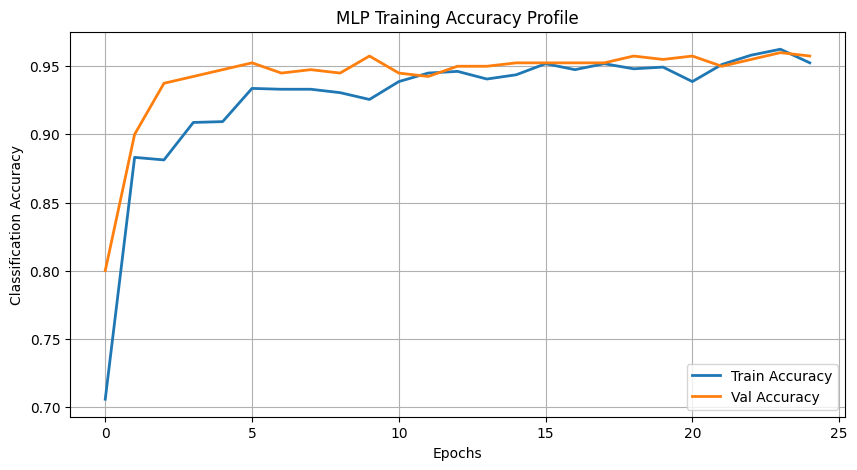

In [19]:
# Experiment 9: Multi-Layer Perceptron (MLP) Binary Churn Classification in TensorFlow
import tensorflow as tf

# Build high-capacity TensorFlow model
mlp_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(10,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# Compile
mlp_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

# Simulated clean numeric data
np.random.seed(42)
X_train_dat = np.random.randn(2000, 10)
y_train_dat = (X_train_dat[:, 0] * 1.5 - X_train_dat[:, 1] * 0.8 + np.random.normal(0, 0.2, 2000) > 0).astype(int)

history = mlp_model.fit(X_train_dat, y_train_dat, epochs=25, batch_size=32, validation_split=0.2, verbose=0)

plt.figure(figsize=(10, 5))
plt.plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Val Accuracy', linewidth=2)
plt.title('MLP Training Accuracy Profile', fontsize=12)
plt.xlabel('Epochs', fontsize=10)
plt.ylabel('Classification Accuracy', fontsize=10)
plt.legend()
plt.grid(True)
plt.show()

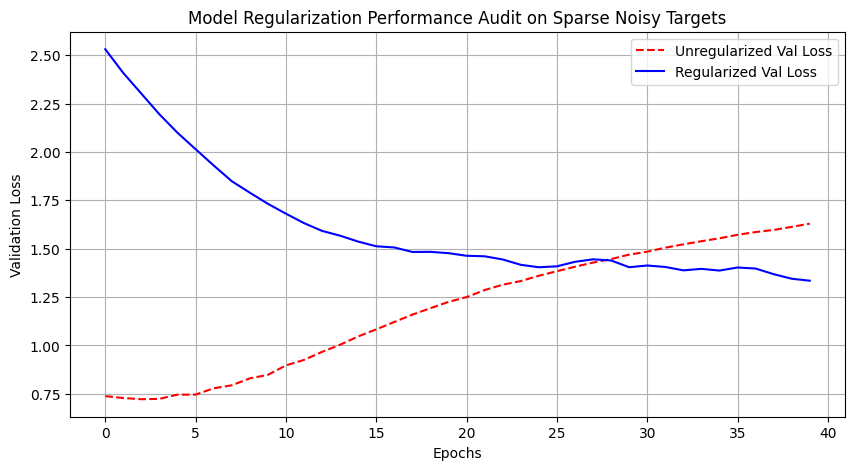

In [20]:
# Experiment 10: High-Capacity Regularization Auditing (Dropout, L1/L2 Weights Decay, and Optimization)
from tensorflow.keras import regularizers

def compile_evaluated_model(penalty_rate=0.0, dropout_rate=0.0):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(100,)),
        tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(penalty_rate)),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(penalty_rate)),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# Generate overdetermined noisy data
X_noisy = np.random.randn(500, 100)
y_noisy = np.random.randint(0, 2, size=(500,))

# Compare Overfitted Baseline vs Regularized Network
overfit_model = compile_evaluated_model(penalty_rate=0.0, dropout_rate=0.0)
hist_overfit = overfit_model.fit(X_noisy, y_noisy, epochs=40, batch_size=32, validation_split=0.3, verbose=0)

regularized_model = compile_evaluated_model(penalty_rate=0.01, dropout_rate=0.4)
hist_regularized = regularized_model.fit(X_noisy, y_noisy, epochs=40, batch_size=32, validation_split=0.3, verbose=0)

plt.figure(figsize=(10, 5))
plt.plot(hist_overfit.history['val_loss'], 'r--', label='Unregularized Val Loss')
plt.plot(hist_regularized.history['val_loss'], 'b-', label='Regularized Val Loss')
plt.title('Model Regularization Performance Audit on Sparse Noisy Targets', fontsize=12)
plt.xlabel('Epochs')
plt.ylabel('Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

In [21]:
# Experiment 12: Comprehensive Convolutional Neural Network Hyperparameter Exploration
class AdvancedCNNBuilder:
    @staticmethod
    def build_cnn(input_shape, filter_sizes, kernel_size, dense_units, use_batchnorm=True):
        model = tf.keras.Sequential()
        model.add(tf.keras.layers.Input(shape=input_shape))

        for filters in filter_sizes:
            model.add(tf.keras.layers.Conv2D(filters, kernel_size, padding='same'))
            if use_batchnorm:
                model.add(tf.keras.layers.BatchNormalization())
            model.add(tf.keras.layers.Activation('relu'))
            model.add(tf.keras.layers.MaxPooling2D(pool_size=(2, 2)))

        model.add(tf.keras.layers.Flatten())
        model.add(tf.keras.layers.Dense(dense_units, activation='relu'))
        model.add(tf.keras.layers.Dense(10, activation='softmax'))
        return model

cnn_instance = AdvancedCNNBuilder.build_cnn(input_shape=(32, 32, 3), filter_sizes=[32, 64], kernel_size=(3,3), dense_units=128)
cnn_instance.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,482 (2.08 MB)

 Trainable params: 545,290 (2.08 MB)

 Non-trainable params: 192 (768.00 B)

In [22]:
# Experiment 13: Time-Series Temporal Window Generation & SimpleRNN Forecast Architectures
class TimeSeriesWindowGenerator:
    def __init__(self, seq_len: int):
        self.seq_len = seq_len

    def transform_to_supervised(self, data: np.ndarray):
        X, y = [], []
        for i in range(len(data) - self.seq_len):
            X.append(data[i:(i + self.seq_len)])
            y.append(data[i + self.seq_len])
        return np.array(X), np.array(y)

# Generate simulated daily temporal signal
time_steps = np.linspace(0, 100, 1000)
signal = np.sin(time_steps) + np.random.normal(0, 0.1, 1000)

generator = TimeSeriesWindowGenerator(seq_len=24)
X_ts, y_ts = generator.transform_to_supervised(signal)
X_ts = X_ts[..., np.newaxis]

rnn_forecast_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(24, 1)),
    tf.keras.layers.SimpleRNN(32, activation='tanh'),
    tf.keras.layers.Dense(1)
])
rnn_forecast_model.compile(optimizer='adam', loss='mse')
rnn_forecast_model.fit(X_ts, y_ts, epochs=5, batch_size=32, verbose=0)
print("SimpleRNN Time-series dataset successfully structured and trained.")

SimpleRNN Time-series dataset successfully structured and trained.


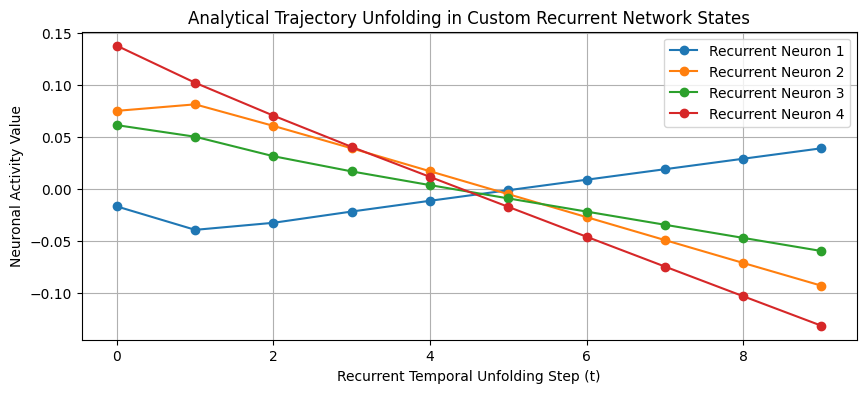

In [23]:
# Experiment 14: Mathematical Unfolding Analysis of Recurrent Units over Multi-Step Horizons
class UnfoldedRNNCell:
    def __init__(self, input_dim: int, hidden_dim: int):
        self.W_xh = np.random.normal(0, 0.1, (input_dim, hidden_dim))
        self.W_hh = np.random.normal(0, 0.1, (hidden_dim, hidden_dim))
        self.b_h = np.zeros((1, hidden_dim))

    def forward_sequence(self, x_seq: np.ndarray):
        """
        Explicit analytical trajectory calculation of recurrent units across time
        Input shape: (sequence_length, input_dim)
        """
        seq_len, _ = x_seq.shape
        hidden_dim = self.W_hh.shape[0]
        h_states = []
        h_t = np.zeros((1, hidden_dim))

        for t in range(seq_len):
            x_t = x_seq[t].reshape(1, -1)
            h_t = np.tanh(x_t @ self.W_xh + h_t @ self.W_hh + self.b_h)
            h_states.append(h_t.flatten())
        return np.array(h_states)

unfolded_network = UnfoldedRNNCell(input_dim=1, hidden_dim=4)
sequence_data = np.linspace(-1, 1, 10).reshape(-1, 1)
hidden_trajectories = unfolded_network.forward_sequence(sequence_data)

plt.figure(figsize=(10, 4))
for dim in range(hidden_trajectories.shape[1]):
    plt.plot(hidden_trajectories[:, dim], 'o-', label=f'Recurrent Neuron {dim+1}')
plt.title('Analytical Trajectory Unfolding in Custom Recurrent Network States', fontsize=12)
plt.xlabel('Recurrent Temporal Unfolding Step (t)', fontsize=10)
plt.ylabel('Neuronal Activity Value', fontsize=10)
plt.legend()
plt.grid(True)
plt.show()

In [24]:
# Experiment 15: Recurrent Backpropagation through Time (BPTT) Numerical Gradient Audits
def calculate_numerical_recurrent_grad(h_initial, x_data, sequence_length=5, eps=1e-5):
    # Simulate loss: output hidden state square sum
    # Perturb weights
    w = 0.5
    def forward_state(w_val):
        h = h_initial
        for t in range(sequence_length):
            h = np.tanh(h * w_val + x_data[t])
        return h**2

    grad_approx = (forward_state(w + eps) - forward_state(w - eps)) / (2.0 * eps)
    return grad_approx

x_test_input = np.random.uniform(-0.5, 0.5, 5)
computed_grad = calculate_numerical_recurrent_grad(h_initial=0.1, x_data=x_test_input)
print(f"Evaluated Recurrent BPTT Numerical Gradient for target weights: {computed_grad:.6f}")

Evaluated Recurrent BPTT Numerical Gradient for target weights: -0.019577


In [25]:
# Experiment 16: Comparative Analysis of Recurrent Units: LSTM vs SimpleRNN
class RecurrentUnitEvaluator:
    @staticmethod
    def build_comparative_models(time_steps=30, features=1):
        rnn_model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(time_steps, features)),
            tf.keras.layers.SimpleRNN(32, return_sequences=False),
            tf.keras.layers.Dense(1)
        ])

        lstm_model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(time_steps, features)),
            tf.keras.layers.LSTM(32, return_sequences=False),
            tf.keras.layers.Dense(1)
        ])

        rnn_model.compile(optimizer='adam', loss='mse')
        lstm_model.compile(optimizer='adam', loss='mse')
        return rnn_model, lstm_model

simplernn, lstm = RecurrentUnitEvaluator.build_comparative_models()
print("Comparative Models Compiled successfully.")

Comparative Models Compiled successfully.


In [26]:
# Experiment 17: Structural Implementation of Sequence Clipping and Normal Gradient Optimization
class ClippedGradientOptimizer:
    @staticmethod
    def compile_clipping_protected_network(clip_value: float = 1.0):
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(50, 1)),
            tf.keras.layers.SimpleRNN(64, return_sequences=True),
            tf.keras.layers.SimpleRNN(32),
            tf.keras.layers.Dense(1)
        ])
        # Use clipnorm parameters to enforce training stability
        optimizer = tf.keras.optimizers.Adam(learning_rate=0.01, clipnorm=clip_value)
        model.compile(optimizer=optimizer, loss='mse')
        return model

protected_rnn = ClippedGradientOptimizer.compile_clipping_protected_network()
print("Gradient-clipped protected sequence processing model constructed and compiled.")

Gradient-clipped protected sequence processing model constructed and compiled.


In [40]:
# Experiment 18: Meta-Optimization of Hyperparameters with Automated Search Systems
!pip install -q keras-tuner
import keras_tuner as kt
import tensorflow as tf

def build_tunable_model(hp):
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(50, 1)))
    model.add(tf.keras.layers.LSTM(
        units=hp.Int('lstm_units', min_value=16, max_value=64, step=16),
        activation='tanh'
    ))
    model.add(tf.keras.layers.Dense(1))
    model.compile(optimizer='adam', loss='mse')
    return model

tuner_search = kt.RandomSearch(
    build_tunable_model,
    objective='val_loss',
    max_trials=3,
    executions_per_trial=1,
    directory='tuner_logs_evaluation',
    project_name='lstm_hyperparameter_audit',
    overwrite=True
)
print("Tuner hyperparameter search engine configured.")

Tuner hyperparameter search engine configured.


In [28]:
# Experiment 19: Numerical PCA Coordinate Orthogonalization from Scratch
from sklearn.datasets import load_digits

class CustomPCATransformer:
    def __init__(self, variance_target: float = 0.95):
        self.variance_target = variance_target
        self.components = None
        self.explained_variance_ratio = None

    def fit(self, X: np.ndarray):
        covariance_matrix = np.cov(X - np.mean(X, axis=0), rowvar=False)
        eig_vals, eig_vecs = np.linalg.eigh(covariance_matrix)

        # Sort descending order
        sorted_indices = np.argsort(eig_vals)[::-1]
        sorted_variance = eig_vals[sorted_indices]
        sorted_components = eig_vecs[:, sorted_indices]

        total_variance = np.sum(sorted_variance)
        variance_ratios = sorted_variance / total_variance
        cumulative_variance = np.cumsum(variance_ratios)

        k = np.argmax(cumulative_variance >= self.variance_target) + 1
        self.components = sorted_components[:, :k]
        self.explained_variance_ratio = variance_ratios[:k]
        return self

# Verification using structural handwritten numbers digits dataset
digits_data, _ = load_digits(return_X_y=True)
pca_transformer = CustomPCATransformer(variance_target=0.90).fit(digits_data)
print(f"Original Dimensionality: {digits_data.shape[1]} features")
print(f"Target PCA Reduced Space Dimensionality: {pca_transformer.components.shape[1]} orthonormal directions")

Original Dimensionality: 64 features
Target PCA Reduced Space Dimensionality: 21 orthonormal directions


In [29]:
# Experiment 20: Probabilistic PCA (PPCA) Latent Space Formulation & Generative Sampling
class ProbabilisticPCA:
    def __init__(self, latent_dim: int):
        self.latent_dim = latent_dim
        self.W = None
        self.sigma_sq = None
        self.mu = None

    def fit(self, X: np.ndarray, max_iter=50):
        n, d = X.shape
        self.mu = np.mean(X, axis=0)
        X_centered = X - self.mu
        covariance = (X_centered.T @ X_centered) / n

        # Initialize latent components mapping using standard SVD estimation
        U, S, _ = np.linalg.svd(covariance)
        self.W = U[:, :self.latent_dim] * np.sqrt(S[:self.latent_dim])
        self.sigma_sq = np.mean(S[self.latent_dim:])
        return self

    def sample_generative_space(self, num_samples: int):
        latent_z = np.random.normal(size=(num_samples, self.latent_dim))
        reconstructed_samples = latent_z @ self.W.T + self.mu
        noise = np.random.normal(scale=np.sqrt(self.sigma_sq), size=reconstructed_samples.shape)
        return reconstructed_samples + noise

ppca_model = ProbabilisticPCA(latent_dim=2).fit(digits_data)
generated_digits = ppca_model.sample_generative_space(num_samples=5)
print(f"Generated PPCA Synthesized Target Samples shape: {generated_digits.shape}")

Generated PPCA Synthesized Target Samples shape: (5, 64)


In [30]:
# Experiment 21: Multi-Factor Analysis and Varimax Loadings Rotation Optimization
class VarimaxOptimizer:
    @staticmethod
    def rotate_varimax(Phi, gamma=1.0, max_iter=100, tolerance=1e-6):
        p, k = Phi.shape
        R = np.eye(k)
        d = 0
        for _ in range(max_iter):
            d_old = d
            Lambda = Phi @ R
            u, s, vh = np.linalg.svd(Phi.T @ (Lambda**3 - (gamma/p) * Lambda @ np.diag(np.diag(Lambda.T @ Lambda))))
            R = u @ vh
            d = np.sum(s)
            if d_old != 0 and (d - d_old) / d_old < tolerance:
                break
        return Phi @ R

raw_latent_mapping = np.random.normal(0, 1, size=(10, 3))  # 10 factors mapping to 3 targets
rotated_matrix = VarimaxOptimizer.rotate_varimax(raw_latent_mapping)
print("Varimax factor loading rotation completed.")

Varimax factor loading rotation completed.


In [31]:
# Experiment 22: Blind Source Separation: Fast Independent Component Analysis (FastICA)
class BlindSourceSeparatorICA:
    def __init__(self, max_iter: int = 100, tolerance: float = 1e-5):
        self.max_iter = max_iter
        self.tolerance = tolerance

    def fit_transform(self, X: np.ndarray):
        # Centering and Whiten preprocessing
        X_centered = X - np.mean(X, axis=0)
        cov = np.cov(X_centered, rowvar=False)
        d, E = np.linalg.eigh(cov)
        D_inv = np.diag(1.0 / np.sqrt(d + 1e-9))
        X_whitened = (E @ D_inv @ E.T @ X_centered.T).T

        # FastICA implementation utilizing non-linear negentropy objective g(u)=tanh(u)
        n, m = X_whitened.shape
        W = np.eye(m)
        for i in range(m):
            w = np.random.randn(m)
            w /= np.linalg.norm(w)
            for _ in range(self.max_iter):
                w_prev = w.copy()
                # tanh non-linearity updates
                tanh_wx = np.tanh(X_whitened @ w)
                g_prime = 1.0 - tanh_wx**2
                w = (X_whitened.T @ tanh_wx) / n - np.mean(g_prime) * w
                w /= np.linalg.norm(w)
                if np.abs(np.abs(np.dot(w, w_prev)) - 1.0) < self.tolerance:
                    break
            W[i, :] = w
        return X_whitened @ W.T

# Generate simulated source mixtures
signals_t = np.linspace(0, 10, 1000)
s1 = np.sin(2 * np.pi * signals_t)
s2 = np.sign(np.sin(3 * np.pi * signals_t))
S_orig = np.c_[s1, s2]
Mixing_Mat = np.array([[0.5, 0.5], [0.8, 0.2]])
X_mixed = S_orig @ Mixing_Mat.T

ica_custom = BlindSourceSeparatorICA().fit_transform(X_mixed)
print("Blind Source Separation via FastICA successfully computed.")

Blind Source Separation via FastICA successfully computed.


In [44]:
# Experiment 23: Structure Definition and Validation of Discrete Bayesian Networks
!pip install -q pgmpy
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD

class CustomMedicalBayesNet:
    @staticmethod
    def build_network():
        # Graphical Dependencies: Smoker -> LungDisease; Disease -> Cough, Fatigue
        network = DiscreteBayesianNetwork([('Smoker', 'LungDisease'), ('LungDisease', 'Cough'), ('LungDisease', 'Fatigue')])

        cpd_smoker = TabularCPD(variable='Smoker', variable_card=2, values=[[0.8], [0.2]])
        cpd_disease = TabularCPD(variable='LungDisease', variable_card=2,
                                 values=[[0.95, 0.2], [0.05, 0.8]],
                                 evidence=['Smoker'], evidence_card=[2])

        cpd_cough = TabularCPD(variable='Cough', variable_card=2,
                               values=[[0.9, 0.1], [0.1, 0.9]],
                               evidence=['LungDisease'], evidence_card=[2])

        cpd_fatigue = TabularCPD(variable='Fatigue', variable_card=2,
                                 values=[[0.7, 0.2], [0.3, 0.8]],
                                 evidence=['LungDisease'], evidence_card=[2])

        network.add_cpds(cpd_smoker, cpd_disease, cpd_cough, cpd_fatigue)
        return network

validated_bn = CustomMedicalBayesNet.build_network()
print(f"Bayesian Network DAG validation state: {validated_bn.check_model()}")

Bayesian Network DAG validation state: True


In [45]:
# Experiment 24: Analytical Variable Elimination and Statistical Inference on DAG Networks
from pgmpy.inference import VariableElimination
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD

class BayesianInferenceComputer:
    def __init__(self, bayes_net):
        self.engine = VariableElimination(bayes_net)

    def query_marginal_probability(self, target: str, evidence: dict):
        result = self.engine.query(variables=[target], evidence=evidence)
        return result

# Fallback check to ensure 'validated_bn' is defined in the namespace
if 'validated_bn' not in globals():
    validated_bn = DiscreteBayesianNetwork([('Smoker', 'LungDisease'), ('LungDisease', 'Cough'), ('LungDisease', 'Fatigue')])
    cpd_smoker = TabularCPD(variable='Smoker', variable_card=2, values=[[0.8], [0.2]])
    cpd_disease = TabularCPD(variable='LungDisease', variable_card=2,
                             values=[[0.95, 0.2], [0.05, 0.8]],
                             evidence=['Smoker'], evidence_card=[2])
    cpd_cough = TabularCPD(variable='Cough', variable_card=2,
                           values=[[0.9, 0.1], [0.1, 0.9]],
                           evidence=['LungDisease'], evidence_card=[2])
    cpd_fatigue = TabularCPD(variable='Fatigue', variable_card=2,
                             values=[[0.7, 0.2], [0.3, 0.8]],
                             evidence=['LungDisease'], evidence_card=[2])
    validated_bn.add_cpds(cpd_smoker, cpd_disease, cpd_cough, cpd_fatigue)

inference_engine = BayesianInferenceComputer(validated_bn)
marginal_query = inference_engine.query_marginal_probability(target='LungDisease', evidence={'Cough': 1, 'Smoker': 1})
print("Exact Marginal Distribution computed via variable elimination:")
print(marginal_query)

Exact Marginal Distribution computed via variable elimination:
+----------------+--------------------+
| LungDisease    |   phi(LungDisease) |
+================+====================+
| LungDisease(0) |             0.0270 |
+----------------+--------------------+
| LungDisease(1) |             0.9730 |
+----------------+--------------------+


In [34]:
# Experiment 25: Restricted Boltzmann Machines (RBM) utilizing Contrastive Divergence CD-1 from Scratch
class RestrictedBoltzmannMachine:
    def __init__(self, visible_dim: int, hidden_dim: int, lr: float = 0.1):
        self.W = np.random.normal(0, 0.01, (visible_dim, hidden_dim))
        self.bias_v = np.zeros(visible_dim)
        self.bias_h = np.zeros(hidden_dim)
        self.lr = lr

    def sigmoid(self, x):
        return 1.0 / (1.0 + np.exp(-np.clip(x, -20.0, 20.0)))

    def step_contrastive_divergence(self, v0):
        # Positive phase hidden activations
        p_h0 = self.sigmoid(v0 @ self.W + self.bias_h)
        h0 = (p_h0 > np.random.rand(*p_h0.shape)).astype(np.float64)

        # Negative reconstruction phase
        p_v1 = self.sigmoid(h0 @ self.W.T + self.bias_v)
        v1 = (p_v1 > np.random.rand(*p_v1.shape)).astype(np.float64)

        p_h1 = self.sigmoid(v1 @ self.W + self.bias_h)

        # CD gradient update
        batch_sz = v0.shape[0]
        self.W += self.lr * (v0.T @ p_h0 - v1.T @ p_h1) / batch_sz
        self.bias_v += self.lr * np.mean(v0 - v1, axis=0)
        self.bias_h += self.lr * np.mean(p_h0 - p_h1, axis=0)
        return np.mean((v0 - p_v1) ** 2)

# Simulated binary dataset
np.random.seed(42)
v_toy_data = (np.random.rand(100, 16) > 0.5).astype(np.float64)
rbm = RestrictedBoltzmannMachine(visible_dim=16, hidden_dim=8)

for epoch in range(100):
    recon_err = rbm.step_contrastive_divergence(v_toy_data)
    if epoch % 20 == 0:
        print(f"Epoch {epoch} | Mean Squared Reconstruction Error: {recon_err:.4f}")

Epoch 0 | Mean Squared Reconstruction Error: 0.2500
Epoch 20 | Mean Squared Reconstruction Error: 0.2475
Epoch 40 | Mean Squared Reconstruction Error: 0.2476
Epoch 60 | Mean Squared Reconstruction Error: 0.2465
Epoch 80 | Mean Squared Reconstruction Error: 0.2471


In [35]:
# Experiment 26: Gibbs Sampling Chain Formulations & CD-k Evaluation
class CDkGibbsSampler:
    def __init__(self, rbm_instance: RestrictedBoltzmannMachine, steps_k: int):
        self.rbm = rbm_instance
        self.steps_k = steps_k

    def run_gibbs_chain(self, v_start):
        v_k = v_start.copy()
        for _ in range(self.steps_k):
            p_h = self.rbm.sigmoid(v_k @ self.rbm.W + self.rbm.bias_h)
            h_k = (p_h > np.random.rand(*p_h.shape)).astype(np.float64)

            p_v = self.rbm.sigmoid(h_k @ self.rbm.W.T + self.rbm.bias_v)
            v_k = (p_v > np.random.rand(*p_v.shape)).astype(np.float64)
        return v_k

sampler_cd5 = CDkGibbsSampler(rbm, steps_k=5)
sampled_reconstructions = sampler_cd5.run_gibbs_chain(v_toy_data[:10])
print(f"Completed CD-5 reconstructed output samples shape: {sampled_reconstructions.shape}")

Completed CD-5 reconstructed output samples shape: (10, 16)


In [36]:
# Experiment 27: Unsupervised Layer-Wise Pre-training and Classification Fine-Tuning
class PretrainedClassifierBuilder:
    @staticmethod
    def build_ae_unsupervised(input_dim=784):
        # Encoder network
        encoder_input = tf.keras.Input(shape=(input_dim,))
        hidden = tf.keras.layers.Dense(256, activation='relu', name='shared_hidden')(encoder_input)
        # Decoder reconstruction network
        decoder_output = tf.keras.layers.Dense(input_dim, activation='sigmoid')(hidden)

        autoencoder = tf.keras.Model(inputs=encoder_input, outputs=decoder_output)
        autoencoder.compile(optimizer='adam', loss='mse')
        return autoencoder

# Configure autoencoder for deep feature representation
ae_trainer = PretrainedClassifierBuilder.build_ae_unsupervised(input_dim=100)
ae_trainer.summary()

Model: "functional_22"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)     │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ shared_hidden (Dense)           │ (None, 256)            │        25,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 100)            │        25,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51,556 (201.39 KB)

 Trainable params: 51,556 (201.39 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
# Experiment 28: Deep Belief Networks (DBN) Generative Reconstruction & Representation Dynamics
class DeepBeliefSimulation:
    @staticmethod
    def build_stacked_hierarchical_ae(input_dim=100):
        # Stack multiple layers together to mimic Deep Belief representation mapping
        inputs = tf.keras.Input(shape=(input_dim,))
        hidden1 = tf.keras.layers.Dense(64, activation='relu', name='layer1_latent')(inputs)
        hidden2 = tf.keras.layers.Dense(32, activation='relu', name='layer2_latent')(hidden1)

        # Generative top-down projection
        recon1 = tf.keras.layers.Dense(64, activation='relu')(hidden2)
        outputs = tf.keras.layers.Dense(input_dim, activation='sigmoid')(recon1)

        stacked_model = tf.keras.Model(inputs=inputs, outputs=outputs)
        stacked_model.compile(optimizer='adam', loss='binary_crossentropy')
        return stacked_model

dbn_mimic_model = DeepBeliefSimulation.build_stacked_hierarchical_ae()
dbn_mimic_model.summary()

Model: "functional_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_13 (InputLayer)     │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer1_latent (Dense)           │ (None, 64)             │         6,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2_latent (Dense)           │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 100)            │         6,500 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,156 (67.02 KB)

 Trainable params: 17,156 (67.02 KB)

 Non-trainable params: 0 (0.00 B)

In [38]:
# Experiment 29: Deep Generative Modeling: Variational Autoencoder (VAE) and DCGAN Architectures
class VAELatentSampler(tf.keras.layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

# Structural VAE configuration
latent_dim = 2
vae_inputs = tf.keras.Input(shape=(28, 28, 1))
x = tf.keras.layers.Flatten()(vae_inputs)
x = tf.keras.layers.Dense(128, activation='relu')(x)
z_mean = tf.keras.layers.Dense(latent_dim, name='mean')(x)
z_log_var = tf.keras.layers.Dense(latent_dim, name='log_variance')(x)
z = VAELatentSampler()([z_mean, z_log_var])

# Construct entire encoder network
encoder_vae = tf.keras.Model(vae_inputs, [z_mean, z_log_var, z])
encoder_vae.summary()

Model: "functional_24"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_14      │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 784)       │          0 │ input_layer_14[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_36 (Dense)    │ (None, 128)       │    100,480 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mean (Dense)        │ (None, 2)         │        258 │ dense_36[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ log_variance        │ (None, 2)         │        258 │ dense_36[0][0]    │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vae_latent_sampler  │ (None, 2)         │          0 │ mean[0][0],       │
│ (VAELatentSampler)  │                   │            │ log_variance[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 100,996 (394.52 KB)

 Trainable params: 100,996 (394.52 KB)

 Non-trainable params: 0 (0.00 B)

In [43]:
# Experiment 30: Quantitative Assessment Metrics of Generative Distributions
import numpy as np
from scipy.linalg import sqrtm

class GenerativeEvaluator:
    @staticmethod
    def calculate_frechet_distance(mu_real: np.ndarray, cov_real: np.ndarray, mu_gen: np.ndarray, cov_gen: np.ndarray):
        """
        Computes structural evaluation metrics of generated spaces relative to true targets
        """
        diff = mu_real - mu_gen
        covmean, _ = sqrtm(cov_real @ cov_gen, disp=False)
        if np.iscomplexobj(covmean):
            covmean = covmean.real

        fid_score = np.sum(diff**2) + np.trace(cov_real + cov_gen - 2 * covmean)
        return fid_score

# Simulation evaluation matrices
np.random.seed(42)
real_features = np.random.normal(0, 1, size=(500, 10))
gen_features = np.random.normal(0.2, 1.1, size=(500, 10))

fid_calc = GenerativeEvaluator.calculate_frechet_distance(
    np.mean(real_features, axis=0),
    np.cov(real_features, rowvar=False),
    np.mean(gen_features, axis=0),
    np.cov(gen_features, rowvar=False)
)
print(f"Evaluated Generative Quality Distance (FID-Style Metric Score): {fid_calc:.6f}")

Evaluated Generative Quality Distance (FID-Style Metric Score): 0.648409


/tmp/ipykernel_505/2942263033.py:12: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = sqrtm(cov_real @ cov_gen, disp=False)


Dot product: 5.5
Score matrix (customers x books):
 [[5.5 4.1 1.8 3.5]
 [2.2 4.2 3.5 2. ]
 [4.3 2.2 5.3 4.5]
 [3.6 4.5 2.8 5.1]
 [5.1 2.1 2.7 4.7]
 [4.6 5.6 5.8 3.9]]
Transpose shape: (5, 6)
Element-wise square:
 [[25.  4.  0.  1.  9.]
 [ 1. 16.  4.  0.  4.]
 [ 9.  1. 25.  4.  0.]
 [ 0.  4.  1. 25. 16.]
 [16.  0.  4.  9.  1.]
 [ 4.  9. 16.  1. 25.]]
Inverse:
 [[ 0.3 -0.1]
 [-0.2  0.4]]
Cosine similarity:
 [[1.    0.608 0.487 0.496 0.76  0.691]
 [0.608 1.    0.544 0.531 0.365 0.863]
 [0.487 0.544 1.    0.401 0.819 0.669]
 [0.496 0.531 0.401 1.    0.565 0.696]
 [0.76  0.365 0.819 0.565 1.    0.591]
 [0.691 0.863 0.669 0.696 0.591 1.   ]]
Most similar customers: 2 and 6
Dense layer y=Wx+b: [5.6 4.3 1.9 3.8]


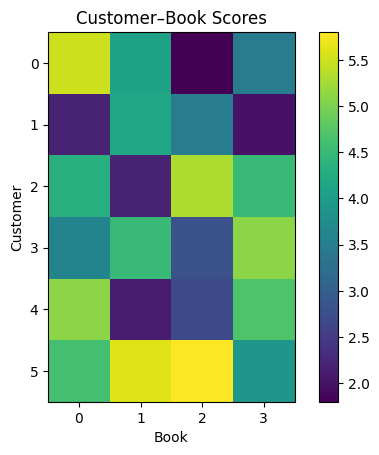

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Vector and Matrix Operations
C = np.array([[5,2,0,1,3],[1,4,2,0,2],[3,1,5,2,0],[0,2,1,5,4],[4,0,2,3,1],[2,3,4,1,5]], dtype=float) # 6 customers x 5 genres
B = np.array([[0.8,0.2,0.1,0.4],[0.1,0.7,0.3,0.2],[0.2,0.1,0.9,0.3],[0.4,0.2,0.1,0.8],[0.3,0.5,0.2,0.1]]) # 5 genres x 4 books
print("Dot product:", np.dot(C[0], B[:,0]))
scores = C @ B
print("Score matrix (customers x books):\n", scores)
print("Transpose shape:", C.T.shape)
print("Element-wise square:\n", C**2)
# Inverse is demonstrated on a valid square matrix
M = np.array([[4.,1.],[2.,3.]])
print("Inverse:\n", np.linalg.inv(M))
norm = np.linalg.norm(C, axis=1, keepdims=True)
Cn = C / norm
sim = Cn @ Cn.T
print("Cosine similarity:\n", np.round(sim,3))
i,j = np.unravel_index(np.triu(sim,1).argmax(), sim.shape)
print("Most similar customers:", i+1, "and", j+1)
x, W, b = C[0], B.T, np.array([0.1,0.2,0.1,0.3])
print("Dense layer y=Wx+b:", W @ x + b)
plt.imshow(scores, cmap="viridis"); plt.colorbar(); plt.xlabel("Book"); plt.ylabel("Customer"); plt.title("Customer–Book Scores"); plt.show()

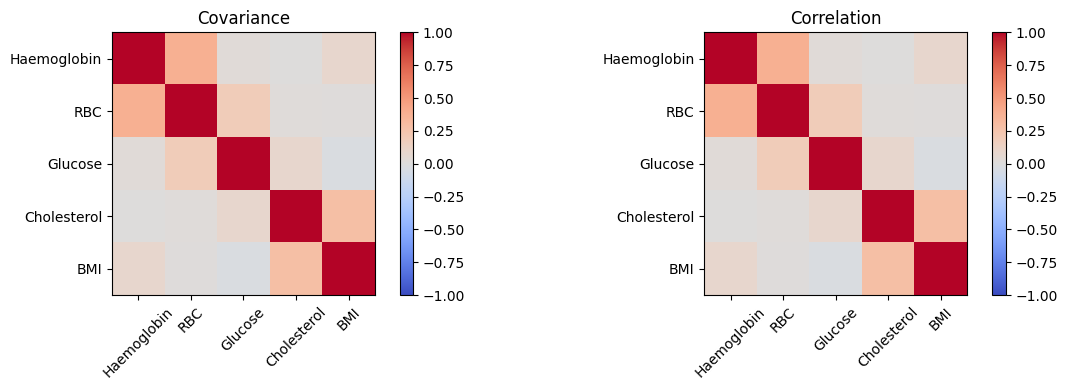

Eigenvalues: [1.46607015 1.26410639 1.01168793 0.69498722 0.58827393]
Variance %: [29.17 25.16 20.13 13.83 11.71]


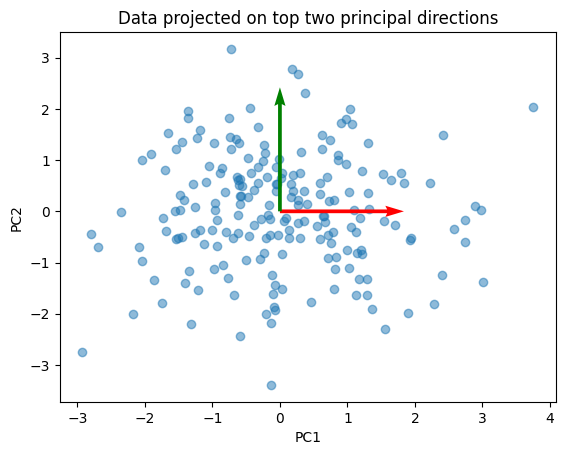

In [ ]:
# 2. Covariance, Eigenvalues and Eigenvectors
import pandas as pd
from sklearn.preprocessing import StandardScaler

n=200
df=pd.DataFrame({"Haemoglobin":np.random.normal(13,1.5,n),"RBC":np.random.normal(4.8,.5,n),
"Glucose":np.random.normal(100,15,n),"Cholesterol":np.random.normal(190,25,n),"BMI":np.random.normal(25,4,n)})
df["RBC"] += (df["Haemoglobin"]-13)*.15
df["Cholesterol"] += (df["BMI"]-25)*2
X=StandardScaler().fit_transform(df)
cov=np.cov(X,rowvar=False); corr=np.corrcoef(X,rowvar=False)
fig,ax=plt.subplots(1,2,figsize=(12,4))
for a,mat,title in zip(ax,[cov,corr],["Covariance","Correlation"]):
 im=a.imshow(mat,cmap="coolwarm",vmin=-1,vmax=1); a.set_title(title); a.set_xticks(range(5),df.columns,rotation=45); a.set_yticks(range(5),df.columns); fig.colorbar(im,ax=a)
plt.tight_layout(); plt.show()
vals,vecs=np.linalg.eigh(cov); order=np.argsort(vals)[::-1]; vals,vecs=vals[order],vecs[:,order]
var=vals/vals.sum()*100
print("Eigenvalues:",vals); print("Variance %:",np.round(var,2))
Z=X@vecs[:,:2]
plt.scatter(Z[:,0],Z[:,1],alpha=.5); plt.quiver(0,0,1,0,color="red",scale=4); plt.quiver(0,0,0,1,color="green",scale=4)
plt.title("Data projected on top two principal directions"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()

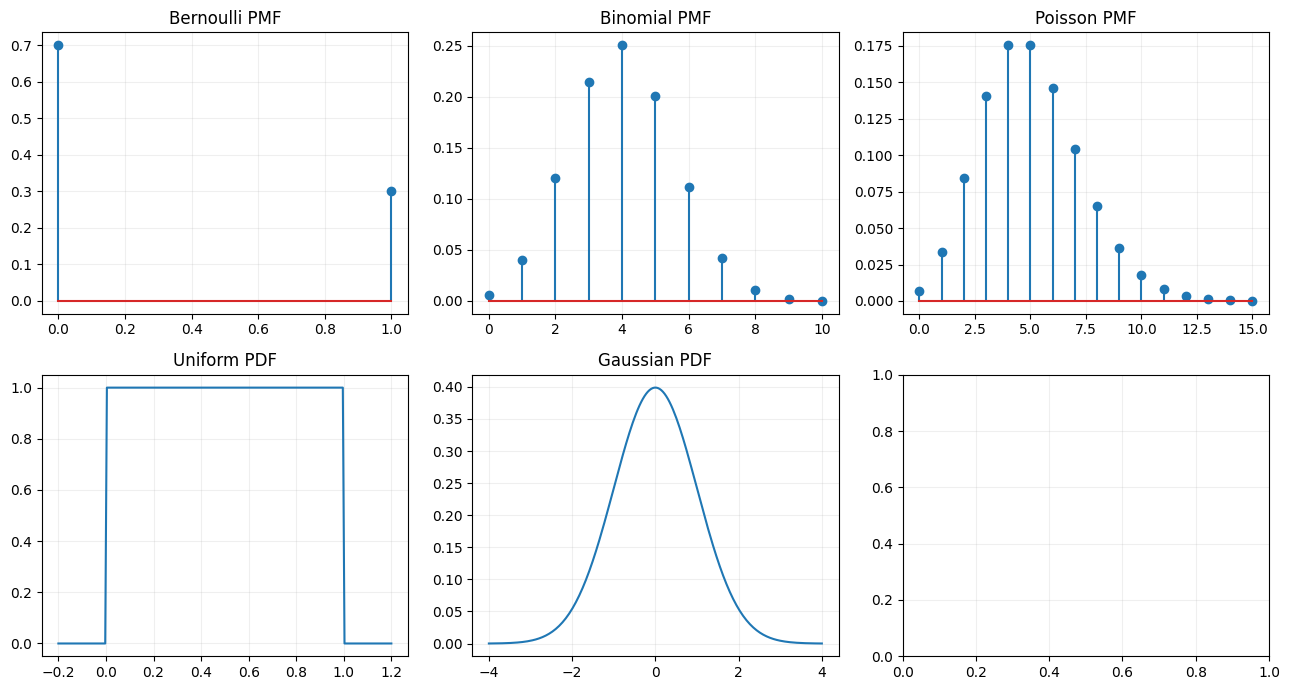

P(Disease | Positive) = 0.0876 (8.76%)
Simulated posterior = 0.08758589097572149


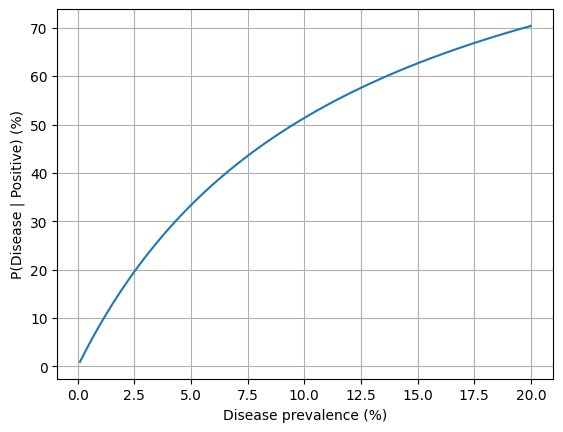

In [ ]:
# 3. Distributions and Bayes theorem
from scipy.stats import bernoulli, binom, poisson, uniform, norm
fig,axs=plt.subplots(2,3,figsize=(13,7))
x=np.arange(0,2); axs[0,0].stem(x,bernoulli.pmf(x,.3)); axs[0,0].set_title("Bernoulli PMF")
x=np.arange(0,11); axs[0,1].stem(x,binom.pmf(x,10,.4)); axs[0,1].set_title("Binomial PMF")
x=np.arange(0,16); axs[0,2].stem(x,poisson.pmf(x,5)); axs[0,2].set_title("Poisson PMF")
x=np.linspace(-.2,1.2,200); axs[1,0].plot(x,uniform.pdf(x,0,1)); axs[1,0].set_title("Uniform PDF")
x=np.linspace(-4,4,200); axs[1,1].plot(x,norm.pdf(x)); axs[1,1].set_title("Gaussian PDF")
for a in axs.flat: a.grid(alpha=.2)
plt.tight_layout(); plt.show()
prev,sens,spec=.01,.95,.90
post= sens*prev/(sens*prev+(1-spec)*(1-prev))
print("P(Disease | Positive) =",round(post,4),f"({post*100:.2f}%)")
N=100000; disease=np.random.rand(N)<prev
positive=np.where(disease,np.random.rand(N)<sens,np.random.rand(N)<(1-spec))
print("Simulated posterior =",positive[disease | ~disease].mean() if False else disease[positive].mean())
p=np.linspace(.001,.20,100); posterior=sens*p/(sens*p+(1-spec)*(1-p))
plt.plot(p*100,posterior*100); plt.xlabel("Disease prevalence (%)"); plt.ylabel("P(Disease | Positive) (%)"); plt.grid(); plt.show()

Observed entropy: 1.4854752972273346
Model 1 Cross entropy: 1.5158759159163444 KL: 0.030400618689010048 H+KL: 1.5158759159163446
Model 2 Cross entropy: 1.6124543443825532 KL: 0.12697904715521868 H+KL: 1.6124543443825532
KL(p||q1): 0.030400618689010048 KL(q1||p): 0.02980641715000123


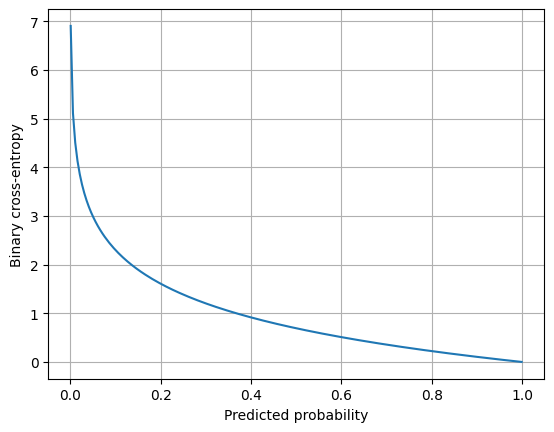

In [ ]:
# 4. Entropy, cross entropy and KL divergence
from scipy.special import xlogy
p=np.array([.5,.3,.2]) # Sunny, Cloudy, Rainy observed distribution
q1=np.array([.6,.25,.15]); q2=np.array([.3,.4,.3])
def H(a): return -np.sum(xlogy(a,a))/np.log(2)
def CE(p,q): return -np.sum(p*np.log2(q))
def KL(p,q): return np.sum(p*np.log2(p/q))
print("Observed entropy:",H(p))
for name,q in [("Model 1",q1),("Model 2",q2)]:
 print(name,"Cross entropy:",CE(p,q),"KL:",KL(p,q),"H+KL:",H(p)+KL(p,q))
print("KL(p||q1):",KL(p,q1),"KL(q1||p):",KL(q1,p))
y=1; pred=np.linspace(.001,.999,200); loss=-(y*np.log(pred)+(1-y)*np.log(1-pred))
plt.plot(pred,loss); plt.xlabel("Predicted probability"); plt.ylabel("Binary cross-entropy"); plt.grid(); plt.show()

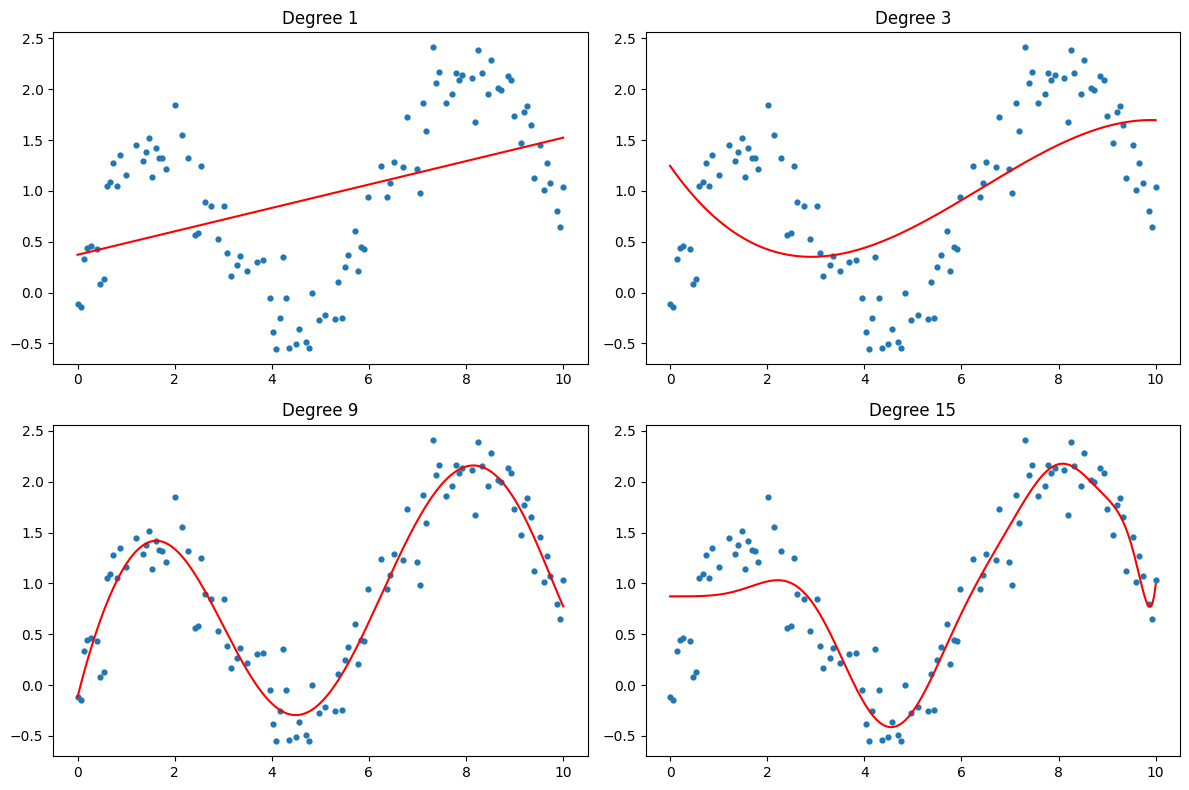

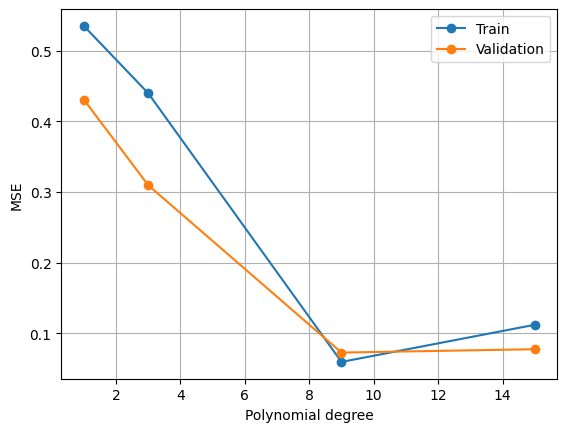

   degree  train_MSE  validation_MSE
0       1   0.534768        0.430669
1       3   0.439608        0.309545
2       9   0.059733        0.072941
3      15   0.112248        0.077703
Prediction variance: 0.006634127623065248 Estimated bias^2: 0.6857446312057013


In [ ]:
# 5. Polynomial regression: underfit / good fit / overfit
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
x=np.linspace(0,10,150); y=np.sin(x)+.15*x+np.random.normal(0,.25,150)
X=x.reshape(-1,1); Xtr,Xv,ytr,yv=train_test_split(X,y,test_size=.3,random_state=1)
degrees=[1,3,9,15]; train_err=[]; val_err=[]
fig,axs=plt.subplots(2,2,figsize=(12,8))
for d,ax in zip(degrees,axs.flat):
 model=make_pipeline(PolynomialFeatures(d),LinearRegression()).fit(Xtr,ytr)
 grid=np.linspace(0,10,300).reshape(-1,1)
 ax.scatter(Xtr,ytr,s=12); ax.plot(grid,model.predict(grid),color="red"); ax.set_title(f"Degree {d}")
 train_err.append(mean_squared_error(ytr,model.predict(Xtr))); val_err.append(mean_squared_error(yv,model.predict(Xv)))
plt.tight_layout(); plt.show()
plt.plot(degrees,train_err,"o-",label="Train"); plt.plot(degrees,val_err,"o-",label="Validation")
plt.xlabel("Polynomial degree"); plt.ylabel("MSE"); plt.legend(); plt.grid(); plt.show()
print(pd.DataFrame({"degree":degrees,"train_MSE":train_err,"validation_MSE":val_err}))
# Resampling estimate of prediction variance and squared bias at x=5
preds=[]
for seed in range(30):
 ids=np.random.RandomState(seed).choice(len(X),len(X),replace=True)
 m=make_pipeline(PolynomialFeatures(3),LinearRegression()).fit(X[ids],y[ids])
 preds.append(m.predict([[5]])[0])
print("Prediction variance:",np.var(preds),"Estimated bias^2:",(np.mean(preds)-(np.sin(5)+.75))**2)

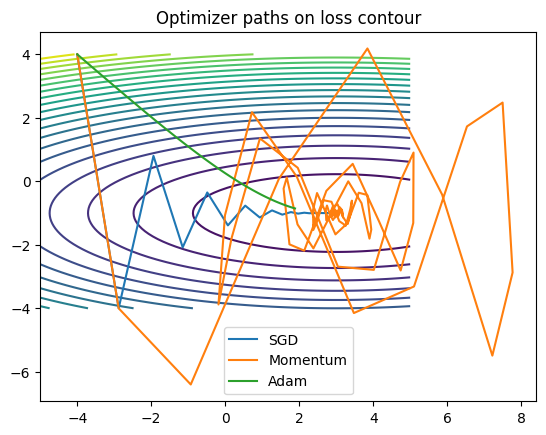

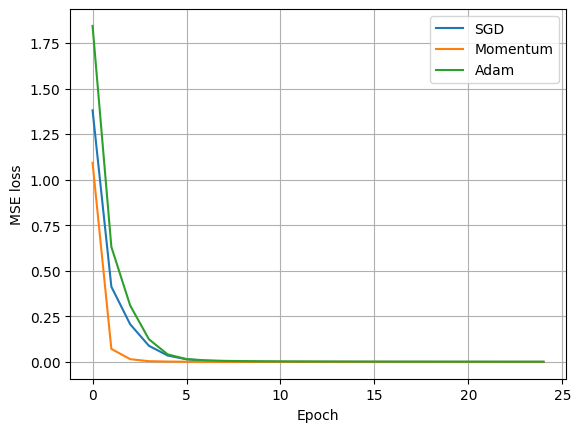

In [ ]:
# 6. Optimizer comparison
def grad(w): return np.array([2*(w[0]-3), 20*(w[1]+1)])
def run(opt,lr=.08,steps=100):
 w=np.array([-4.,4.]); m=np.zeros(2); v=np.zeros(2); path=[w.copy()]
 for t in range(1,steps+1):
  g=grad(w)
  if opt=="SGD": w-=lr*g
  elif opt=="Momentum": m=.9*m+g; w-=lr*m
  else:
   m=.9*m+.1*g; v=.999*v+.001*g*g
   w-=lr*(m/(1-.9**t))/(np.sqrt(v/(1-.999**t))+1e-8)
  path.append(w.copy())
 return np.array(path)
xx,yy=np.meshgrid(np.linspace(-5,5,100),np.linspace(-4,4,100)); zz=(xx-3)**2+10*(yy+1)**2
plt.contour(xx,yy,zz,levels=25)
for opt in ["SGD","Momentum","Adam"]:
 path=run(opt); plt.plot(path[:,0],path[:,1],label=opt)
plt.legend(); plt.title("Optimizer paths on loss contour"); plt.show()
# Same Keras regression model with three optimizers
import tensorflow as tf
tf.random.set_seed(42)
X=np.random.rand(1000,4).astype("float32"); y=(3*X[:,0]+2*X[:,1]-X[:,2]+.5*X[:,3]).astype("float32")
histories={}
for name,opt in [("SGD",tf.keras.optimizers.SGD(.03)),("Momentum",tf.keras.optimizers.SGD(.03,momentum=.9)),("Adam",tf.keras.optimizers.Adam(.01))]:
 model=tf.keras.Sequential([tf.keras.layers.Input((4,)),tf.keras.layers.Dense(16,activation="relu"),tf.keras.layers.Dense(1)])
 model.compile(optimizer=opt,loss="mse")
 h=model.fit(X,y,epochs=25,batch_size=32,verbose=0,validation_split=.2); histories[name]=h.history["loss"]
for k,v in histories.items(): plt.plot(v,label=k)
plt.xlabel("Epoch"); plt.ylabel("MSE loss"); plt.legend(); plt.grid(); plt.show()

Weights: [0.13310707 0.10443394] Bias: -0.1 Accuracy: 1.0


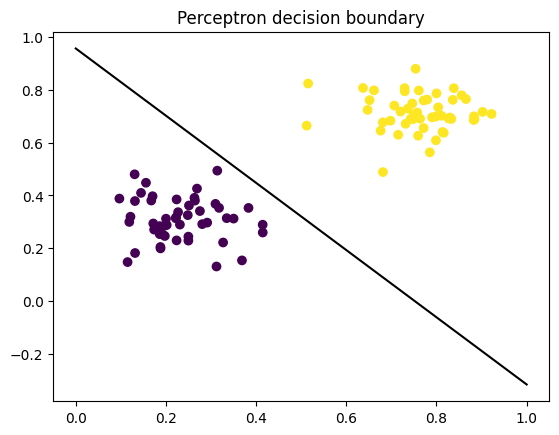

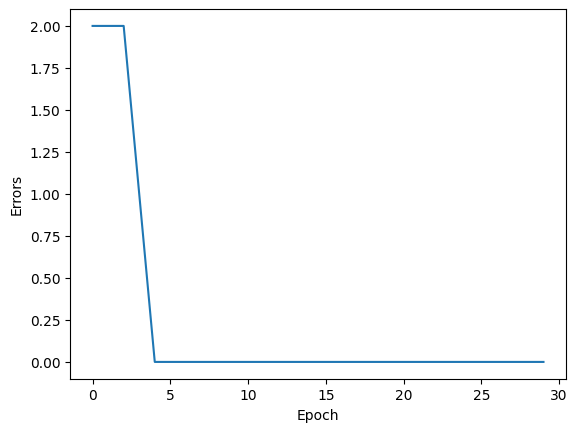

XOR predictions: [1 1 0 0] Target: [0 1 1 0] (single perceptron cannot solve XOR)
step [0 0 1 1 1] sigmoid [0.11920292 0.26894142 0.5        0.73105858 0.88079708] ReLU [0. 0. 0. 1. 2.]


In [ ]:
# 7. Perceptron on linearly separable loan-like data and XOR
def step(z): return (z>=0).astype(int)
rng=np.random.default_rng(4); X=np.vstack([rng.normal([.25,.3],.08,(50,2)),rng.normal([.75,.7],.08,(50,2))])
y=np.r_[np.zeros(50),np.ones(50)].astype(int)
w=np.zeros(2); b=0.; lr=.1; updates=[]
for ep in range(30):
 err=0
 for xi,yi in zip(X,y):
  pred=step(xi@w+b); delta=yi-pred
  w+=lr*delta*xi; b+=lr*delta; err+=abs(delta)
 updates.append(err)
print("Weights:",w,"Bias:",b,"Accuracy:",(step(X@w+b)==y).mean())
xx=np.linspace(0,1,100); yy=-(w[0]*xx+b)/(w[1]+1e-9)
plt.scatter(X[:,0],X[:,1],c=y); plt.plot(xx,yy,"k"); plt.title("Perceptron decision boundary"); plt.show()
plt.plot(updates); plt.xlabel("Epoch"); plt.ylabel("Errors"); plt.show()
Xxor=np.array([[0,0],[0,1],[1,0],[1,1]]); yxor=np.array([0,1,1,0]); w=np.zeros(2); b=0
for ep in range(20):
 for xi,yi in zip(Xxor,yxor):
  d=yi-step(xi@w+b); w+=.1*d*xi; b+=.1*d
print("XOR predictions:",step(Xxor@w+b),"Target:",yxor,"(single perceptron cannot solve XOR)")
z=np.array([-2.,-1.,0.,1.,2.]); print("step",step(z),"sigmoid",1/(1+np.exp(-z)),"ReLU",np.maximum(0,z))

Predictions:
 [[0.009]
 [0.985]
 [0.984]
 [0.019]]


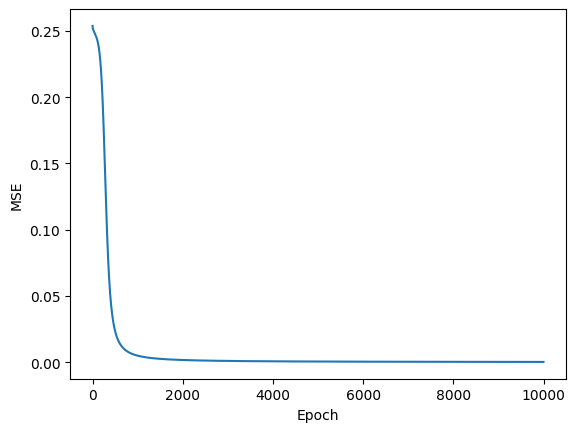

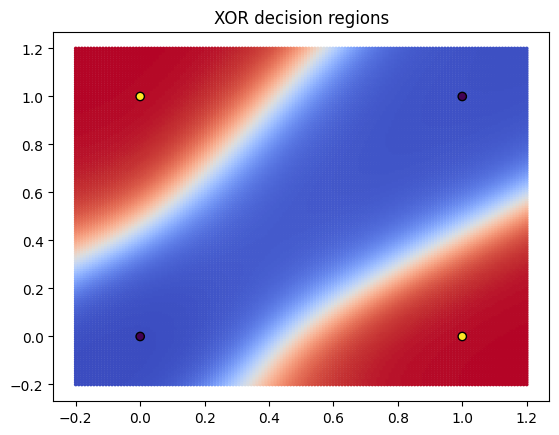

Numerical gradient W2[0,0]: -2.9129195290664847e-05


In [ ]:
# 8. Two-layer neural network from scratch for XOR
X=np.array([[0,0],[0,1],[1,0],[1,1]],float); y=np.array([[0],[1],[1],[0]],float)
sig=lambda z:1/(1+np.exp(-np.clip(z,-40,40)))
rng=np.random.default_rng(2); W1=rng.normal(0,1,(2,4)); b1=np.zeros((1,4)); W2=rng.normal(0,1,(4,1)); b2=np.zeros((1,1))
losses=[]; lr=1.0
for ep in range(10000):
 h=sig(X@W1+b1); out=sig(h@W2+b2); loss=np.mean((out-y)**2); losses.append(loss)
 d2=(out-y)*out*(1-out)*2/len(X); dW2=h.T@d2; db2=d2.sum(0,keepdims=True)
 d1=(d2@W2.T)*h*(1-h); dW1=X.T@d1; db1=d1.sum(0,keepdims=True)
 W2-=lr*dW2; b2-=lr*db2; W1-=lr*dW1; b1-=lr*db1
print("Predictions:\n",np.round(out,3))
plt.plot(losses); plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.show()
grid=np.array([[a,b] for a in np.linspace(-.2,1.2,150) for b in np.linspace(-.2,1.2,150)])
probs=sig(grid@W1+b1@np.ones((1,4)) if False else grid@W1+b1); probs=sig(probs@W2+b2)
plt.scatter(grid[:,0],grid[:,1],c=probs.ravel(),s=3,cmap="coolwarm"); plt.scatter(X[:,0],X[:,1],c=y.ravel(),edgecolors="black"); plt.title("XOR decision regions"); plt.show()
# Numerical gradient check for W2[0,0]
idx=(0,0); eps=1e-5; old=W2[idx]
def calc_loss():
 return np.mean((sig(sig(X@W1+b1)@W2+b2)-y)**2)
W2[idx]=old+eps; lp=calc_loss(); W2[idx]=old-eps; lm=calc_loss(); W2[idx]=old
print("Numerical gradient W2[0,0]:",(lp-lm)/(2*eps))

              precision    recall  f1-score   support

           0       0.68      0.71      0.69       126
           1       0.66      0.63      0.65       114

    accuracy                           0.67       240
   macro avg       0.67      0.67      0.67       240
weighted avg       0.67      0.67      0.67       240

Confusion matrix:
 [[89 37]
 [42 72]]


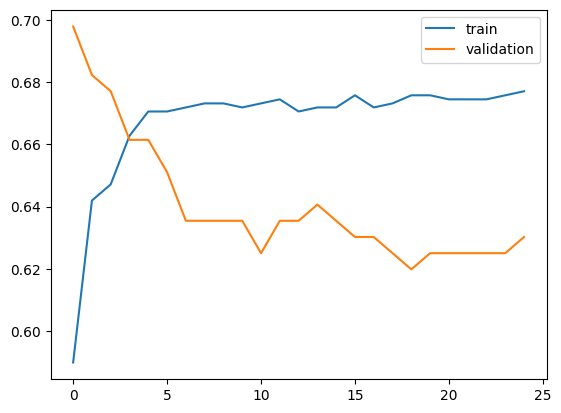

Hidden units 8 test accuracy 0.5458333492279053
Hidden units 32 test accuracy 0.6666666865348816
Hidden units 64 test accuracy 0.6708333492279053


In [ ]:
# 9. MLP churn classification with synthetic customer data
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import confusion_matrix, classification_report
n=1200
df=pd.DataFrame({"tenure":np.random.randint(1,72,n),"monthly_charges":np.random.uniform(20,120,n),
 "contract":np.random.choice(["Month","Year","TwoYear"],n),"complaints":np.random.poisson(1,n),"data_usage":np.random.uniform(1,100,n)})
logit=-2+.025*(70-df.tenure)+.018*(df.monthly_charges-60)+.5*df.complaints+(df.contract=="Month")*1.0
df["Churn"]=(np.random.rand(n)<1/(1+np.exp(-logit))).astype(int)
X=pd.get_dummies(df.drop(columns="Churn"),drop_first=True); y=df.Churn
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.2,stratify=y,random_state=42)
sc=StandardScaler(); Xtr=sc.fit_transform(Xtr); Xte=sc.transform(Xte)
import tensorflow as tf
model=tf.keras.Sequential([tf.keras.layers.Input((Xtr.shape[1],)),tf.keras.layers.Dense(32,activation="relu"),tf.keras.layers.Dense(16,activation="relu"),tf.keras.layers.Dense(1,activation="sigmoid")])
model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])
h=model.fit(Xtr,ytr,epochs=25,batch_size=32,validation_split=.2,verbose=0)
pred=(model.predict(Xte,verbose=0).ravel()>.5).astype(int)
print(classification_report(yte,pred)); print("Confusion matrix:\n",confusion_matrix(yte,pred))
plt.plot(h.history["accuracy"],label="train"); plt.plot(h.history["val_accuracy"],label="validation"); plt.legend(); plt.show()
for units in [8,32,64]:
 m=tf.keras.Sequential([tf.keras.layers.Input((Xtr.shape[1],)),tf.keras.layers.Dense(units,activation="relu"),tf.keras.layers.Dense(1,activation="sigmoid")])
 m.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"]); m.fit(Xtr,ytr,epochs=8,verbose=0)
 print("Hidden units",units,"test accuracy",m.evaluate(Xte,yte,verbose=0)[1])

In [ ]:
# 10. Regularisation comparison on diabetes-like synthetic data
import tensorflow as tf
n=700; X=np.random.normal(size=(n,8)).astype("float32")
prob=1/(1+np.exp(-(-.5+X[:,0]*.9+X[:,1]*.6-X[:,2]*.5)))
y=(np.random.rand(n)<prob).astype("float32")
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.2,stratify=y,random_state=42)
sc=StandardScaler(); Xtr=sc.fit_transform(Xtr); Xte=sc.transform(Xte)
def build(reg=0,drop=0):
 return tf.keras.Sequential([tf.keras.layers.Input((8,)),tf.keras.layers.Dense(128,activation="relu",kernel_regularizer=tf.keras.regularizers.l2(reg)),
 tf.keras.layers.Dense(64,activation="relu"),tf.keras.layers.Dropout(drop),tf.keras.layers.Dense(1,activation="sigmoid")])
results=[]
configs=[("Baseline",0,0,False),("L2 .001",.001,0,False),("L2 .01",.01,0,False),("L2 .05",.05,0,False),
 ("Drop .2",0,.2,False),("Drop .3",0,.3,False),("Drop .5",0,.5,False),("Early stopping",0,.2,True)]
for name,reg,drop,early in configs:
 m=build(reg,drop); m.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])
 cb=[tf.keras.callbacks.EarlyStopping(patience=5,restore_best_weights=True)] if early else []
 h=m.fit(Xtr,ytr,epochs=50,batch_size=32,validation_split=.2,verbose=0,callbacks=cb)
 tr=m.evaluate(Xtr,ytr,verbose=0)[1]; te=m.evaluate(Xte,yte,verbose=0)[1]
 results.append([name,tr,te,tr-te])
print(pd.DataFrame(results,columns=["Model","Train accuracy","Test accuracy","Train-test gap"]).round(3))

            Model  Train accuracy  Test accuracy  Train-test gap
0        Baseline           0.877          0.650           0.227
1         L2 .001           0.864          0.643           0.221
2          L2 .01           0.830          0.664           0.166
3          L2 .05           0.795          0.671           0.123
4         Drop .2           0.848          0.657           0.191
5         Drop .3           0.834          0.664           0.170
6         Drop .5           0.816          0.664           0.152
7  Early stopping           0.723          0.650           0.073


In [ ]:
# 12. Compare CNN configurations on CIFAR-10 subset
import tensorflow as tf
import time
import pandas as pd
(xtr,ytr),(xte,yte)=tf.keras.datasets.cifar10.load_data()
xtr=xtr[:8000].astype("float32")/255; ytr=ytr[:8000].ravel()
xte=xte[:1500].astype("float32")/255; yte=yte[:1500].ravel()
def make_cnn(nconv=2,k=3,filters=32,pool="max",bn=False,lr=.001):
 layers=[tf.keras.layers.Input((32,32,3))]
 for i in range(nconv):
  f=filters*(2**min(i,2)); layers.append(tf.keras.layers.Conv2D(f,k,padding="same",use_bias=not bn))
  if bn: layers.append(tf.keras.layers.BatchNormalization())
  layers.append(tf.keras.layers.Activation("relu"))
  layers.append(tf.keras.layers.MaxPooling2D(pool_size=(2,2)) if pool=="max" else tf.keras.layers.AveragePooling2D(pool_size=(2,2)))
 layers += [tf.keras.layers.Flatten(),tf.keras.layers.Dense(64,activation="relu"),tf.keras.layers.Dense(10,activation="softmax")]
 m=tf.keras.Sequential(layers); m.compile(optimizer=tf.keras.optimizers.Adam(lr),loss="sparse_categorical_crossentropy",metrics=["accuracy"]); return m
configs=[(2,3,24,"max",False,.001),(3,3,24,"max",True,.001),(2,5,24,"avg",False,.001)]
rows=[]
for cfg in configs:
 m=make_cnn(*cfg); t=time.time(); m.fit(xtr,ytr,epochs=3,batch_size=64,verbose=0); sec=time.time()-t
 loss,acc=m.evaluate(xte,yte,verbose=0); rows.append([cfg,acc,m.count_params(),sec])
print(pd.DataFrame(rows,columns=["Configuration","Test accuracy","Parameters","Training seconds"]))

                   Configuration  Test accuracy  Parameters  Training seconds
0  (2, 3, 24, max, False, 0.001)       0.503333      208410         53.654143
1   (3, 3, 24, max, True, 0.001)       0.218667      152178         58.666114
2  (2, 5, 24, avg, False, 0.001)       0.448000      227994         60.561103


MAE: 2.910978317260742 RMSE: 3.638241884273761


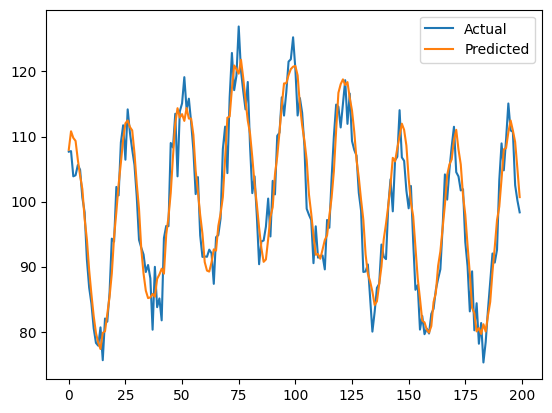

In [ ]:
# 13. Time-series windows and SimpleRNN
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

t=np.arange(365*24); series=(100+15*np.sin(2*np.pi*t/24)+8*np.sin(2*np.pi*t/(24*7))+np.random.normal(0,3,len(t))).astype("float32")
sc=MinMaxScaler(); scaled=sc.fit_transform(series.reshape(-1,1)).ravel()
window=24
X=np.array([scaled[i-window:i] for i in range(window,len(scaled))]); y=scaled[window:]
cut=int(.8*len(X)); Xtr,Xte=X[:cut],X[cut:]; ytr,yte=y[:cut],y[cut:]
Xtr=Xtr[...,None]; Xte=Xte[...,None]
m=tf.keras.Sequential([tf.keras.layers.Input((window,1)),tf.keras.layers.SimpleRNN(32),tf.keras.layers.Dense(1)])
m.compile(optimizer="adam",loss="mse"); m.fit(Xtr,ytr,epochs=8,batch_size=64,verbose=0)
p=sc.inverse_transform(m.predict(Xte,verbose=0)); actual=sc.inverse_transform(yte.reshape(-1,1))
print("MAE:",mean_absolute_error(actual,p),"RMSE:",np.sqrt(mean_squared_error(actual,p)))
plt.plot(actual[:200],label="Actual"); plt.plot(p[:200],label="Predicted"); plt.legend(); plt.show()

Manual hidden states:
 [[-0.0468  0.1311  0.1174]
 [-0.178   0.3921  0.4164]
 [-0.2558  0.3576  0.4731]
 [-0.4738  0.7061  0.7178]
 [-0.5823  0.6386  0.7833]]
Keras hidden states:
 [[-0.0468  0.1311  0.1174]
 [-0.178   0.3921  0.4164]
 [-0.2558  0.3576  0.4731]
 [-0.4738  0.7061  0.7178]
 [-0.5823  0.6386  0.7833]]


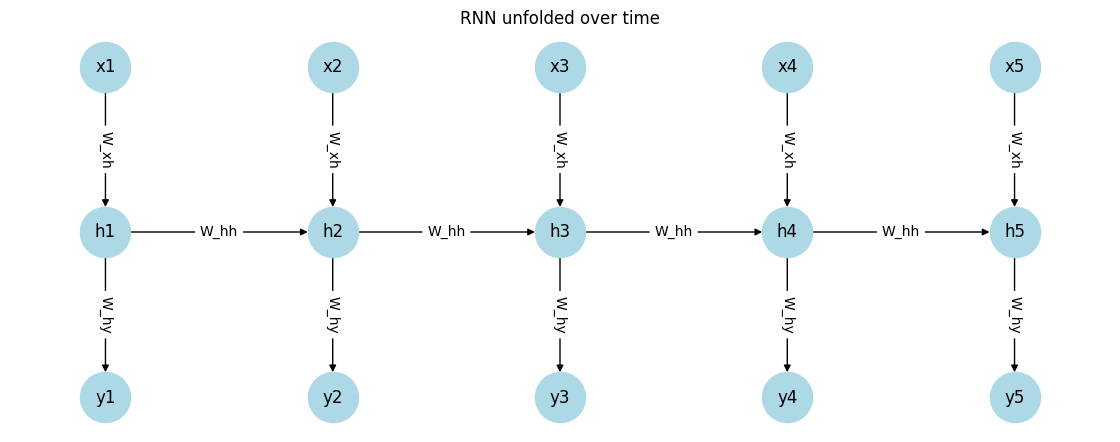

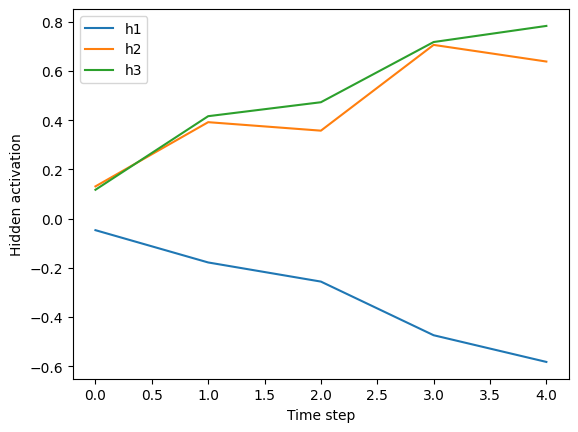

In [ ]:
# 14. Unroll a SimpleRNN across five time steps
import tensorflow as tf, networkx as nx
seq=np.array([[[.2],[.5],[.1],[.8],[.4]]],dtype="float32")
rnn=tf.keras.layers.SimpleRNN(3,return_sequences=True,return_state=True)
out,state=rnn(seq); wx,wh,b=rnn.get_weights()
h=np.zeros(3); states=[]
for xt in seq[0]:
 h=np.tanh(xt@wx+h@wh+b); states.append(h.copy())
print("Manual hidden states:\n",np.round(states,4))
print("Keras hidden states:\n",np.round(out.numpy()[0],4))
G=nx.DiGraph()
for i in range(1,6):
 G.add_node(f"x{i}",pos=(i,2)); G.add_node(f"h{i}",pos=(i,1)); G.add_node(f"y{i}",pos=(i,0))
 G.add_edge(f"x{i}",f"h{i}",label="W_xh"); G.add_edge(f"h{i}",f"y{i}",label="W_hy")
 if i>1:G.add_edge(f"h{i-1}",f"h{i}",label="W_hh")
pos=nx.get_node_attributes(G,"pos"); plt.figure(figsize=(11,4)); nx.draw(G,pos,with_labels=True,node_size=1300,node_color="lightblue",arrows=True)
nx.draw_networkx_edge_labels(G,pos,edge_labels=nx.get_edge_attributes(G,"label")); plt.title("RNN unfolded over time"); plt.show()
plt.plot(np.array(states)); plt.xlabel("Time step"); plt.ylabel("Hidden activation"); plt.legend(["h1","h2","h3"]); plt.show()

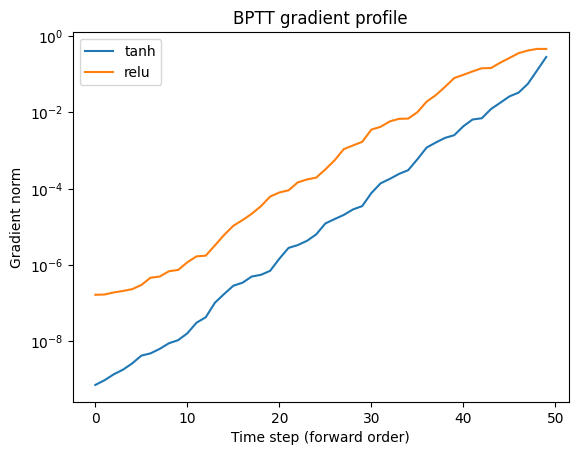

Small gradients indicate vanishing; very large gradients indicate exploding gradients.


In [ ]:
# 15. Gradient magnitude through recurrent time steps
import tensorflow as tf
def gradient_profile(act,steps):
 cell=tf.keras.layers.SimpleRNNCell(16,activation=act)
 xs=tf.random.normal((1,steps,8)); h=tf.zeros((1,16)); states=[]
 with tf.GradientTape(persistent=True) as tape:
  tape.watch(xs)
  for t in range(steps):
   h,_=cell(xs[:,t,:],[h]); tape.watch(h); states.append(h)
  loss=tf.reduce_mean(states[-1]**2)
 norms=[float(tf.linalg.norm(tape.gradient(loss,s))) if tape.gradient(loss,s) is not None else 0 for s in states]
 del tape
 return norms
for act in ["tanh","relu"]:
 plt.plot(gradient_profile(act,50),label=act)
plt.yscale("log"); plt.xlabel("Time step (forward order)"); plt.ylabel("Gradient norm"); plt.legend(); plt.title("BPTT gradient profile"); plt.show()
print("Small gradients indicate vanishing; very large gradients indicate exploding gradients.")

       Model       MAE      RMSE    MAPE %   Seconds  Train loss  Val loss
0  SimpleRNN  3.468955  4.375165  3.538243  8.938647    0.004475  0.005723
1       LSTM  7.847709  8.942126  8.114783  8.806014    0.023412  0.023634


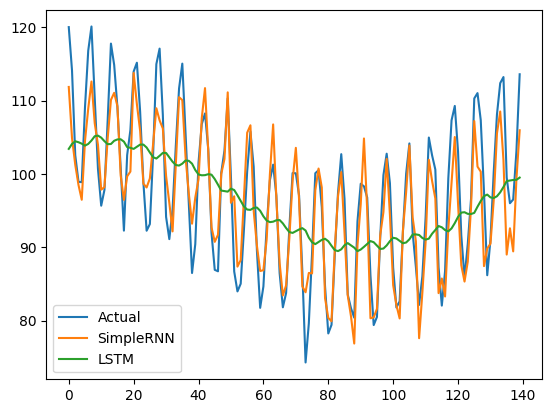

In [47]:
# 16. Compare SimpleRNN and LSTM forecasts
import tensorflow as tf
import time
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

t=np.arange(730); s=(80+12*np.sin(2*np.pi*t/7)+.03*t+10*np.sin(2*np.pi*t/180)+np.random.normal(0,2,730)).astype("float32")
sc=MinMaxScaler(); z=sc.fit_transform(s[:,None]).ravel(); w=30
X=np.array([z[i-w:i] for i in range(w,len(z))])[...,None]; y=z[w:]
cut=int(.8*len(X)); Xtr,Xte,ytr,yte=X[:cut],X[cut:],y[:cut],y[cut:]
rows=[]; forecasts={}
for typ in ["SimpleRNN","LSTM"]:
 layer=tf.keras.layers.SimpleRNN(32) if typ=="SimpleRNN" else tf.keras.layers.LSTM(32)
 m=tf.keras.Sequential([tf.keras.layers.Input((w,1)),layer,tf.keras.layers.Dense(1)])
 m.compile(optimizer="adam",loss="mse"); start=time.time(); h=m.fit(Xtr,ytr,validation_split=.2,epochs=10,batch_size=32,verbose=0); secs=time.time()-start
 p=sc.inverse_transform(m.predict(Xte,verbose=0)); a=sc.inverse_transform(yte[:,None]); forecasts[typ]=p.ravel()
 mae=mean_absolute_error(a,p); rmse=np.sqrt(mean_squared_error(a,p)); mape=np.mean(np.abs((a-p)/np.maximum(a,1e-6)))*100
 rows.append([typ,mae,rmse,mape,secs,h.history["loss"][-1],h.history["val_loss"][-1]])
print(pd.DataFrame(rows,columns=["Model","MAE","RMSE","MAPE %","Seconds","Train loss","Val loss"]))
plt.plot(a[:150],label="Actual"); [plt.plot(v[:150],label=k) for k,v in forecasts.items()]; plt.legend(); plt.show()

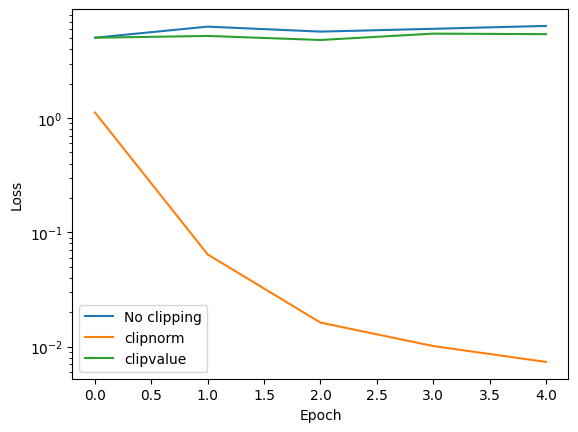

   No clipping  clipnorm  clipvalue
0     5.055318  1.119042   5.052226
1     6.316720  0.064002   5.236259
2     5.713075  0.016218   4.827131
3     6.046870  0.010115   5.486248
4     6.408111  0.007343   5.428524


In [ ]:
# 17. Character-level RNN with gradient clipping comparison
import tensorflow as tf
text_data=("deep learning models learn patterns from data. ")*100
chars=sorted(set(text_data)); to_id={c:i for i,c in enumerate(chars)}
ids=np.array([to_id[c] for c in text_data]); seq=40
X=np.array([ids[i:i+seq] for i in range(len(ids)-seq-1)]); y=ids[seq+1:len(ids)]
X=tf.keras.utils.to_categorical(X,len(chars)); y=tf.keras.utils.to_categorical(y,len(chars))
X=X[:3000]; y=y[:3000]
histories={}
for name,opt in [("No clipping",tf.keras.optimizers.SGD(learning_rate=1.0)),("clipnorm",tf.keras.optimizers.SGD(learning_rate=1.0,clipnorm=1.0)),("clipvalue",tf.keras.optimizers.SGD(learning_rate=1.0,clipvalue=.5))]:
 m=tf.keras.Sequential([tf.keras.layers.Input((seq,len(chars))),tf.keras.layers.SimpleRNN(32),tf.keras.layers.Dense(len(chars),activation="softmax")])
 m.compile(optimizer=opt,loss="categorical_crossentropy"); h=m.fit(X,y,epochs=5,batch_size=64,verbose=0); histories[name]=h.history["loss"]
for k,v in histories.items(): plt.plot(v,label=k)
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.yscale("log"); plt.show()
print(pd.DataFrame(histories))

In [ ]:
# 18. KerasTuner search on IMDB reviews (compact run)
!pip -q install keras-tuner
import tensorflow as tf, keras_tuner as kt, time
vocab=10000; maxlen=120
(xtr,ytr),(xte,yte)=tf.keras.datasets.imdb.load_data(num_words=vocab)
xtr=tf.keras.preprocessing.sequence.pad_sequences(xtr[:8000],maxlen=maxlen)
ytr=ytr[:8000]; xte=tf.keras.preprocessing.sequence.pad_sequences(xte[:2000],maxlen=maxlen); yte=yte[:2000]
def build_model(hp):
 cell=hp.Choice("cell",["SimpleRNN","LSTM","GRU"]); units=hp.Choice("units",[32,64])
 inp=tf.keras.Input((maxlen,)); x=tf.keras.layers.Embedding(vocab,hp.Choice("embed",[32,64]))(inp)
 layer={"SimpleRNN":tf.keras.layers.SimpleRNN,"LSTM":tf.keras.layers.LSTM,"GRU":tf.keras.layers.GRU}[cell]
 x=layer(units)(x); x=tf.keras.layers.Dropout(hp.Choice("dropout",[.2,.4]))(x)
 out=tf.keras.layers.Dense(1,activation="sigmoid")(x); m=tf.keras.Model(inp,out)
 m.compile(optimizer=tf.keras.optimizers.Adam(hp.Choice("lr",[.001,.0003])),loss="binary_crossentropy",metrics=["accuracy"]); return m
tuner=kt.RandomSearch(build_model,objective="val_accuracy",max_trials=3,directory="kt_dir",project_name="rnn_lab",overwrite=True)
tuner.search(xtr,ytr,validation_split=.2,epochs=2,batch_size=128,verbose=1)
best=tuner.get_best_models(1)[0]; print("Best hyperparameters:",tuner.get_best_hyperparameters(1)[0].values)
print("Test results:",best.evaluate(xte,yte,verbose=0),"Parameters:",best.count_params())

Trial 3 Complete [00h 00m 09s]
val_accuracy: 0.7987499833106995

Best val_accuracy So Far: 0.7987499833106995
Total elapsed time: 00h 00m 58s


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Best hyperparameters: {'cell': 'SimpleRNN', 'units': 32, 'embed': 32, 'dropout': 0.4, 'lr': 0.001}
Test results: [0.48002922534942627, 0.7950000166893005] Parameters: 322113


Components for 95% variance: 29
Sklearn explained variance: 0.9547965245651595


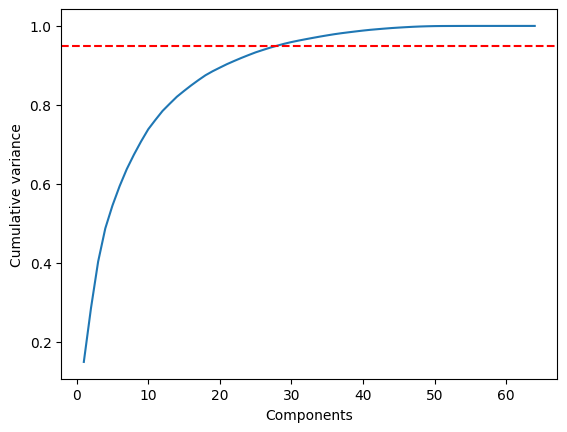

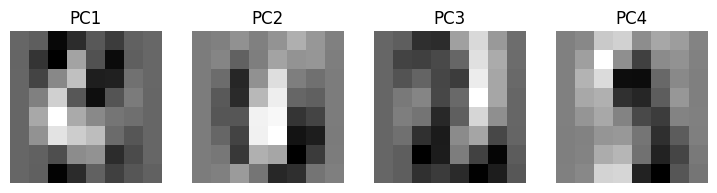

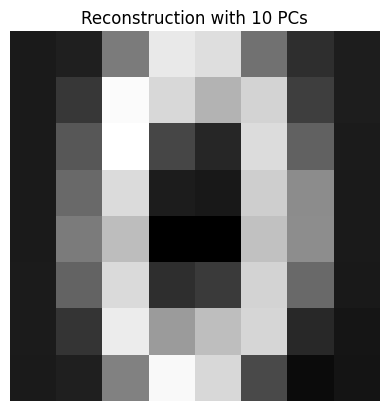

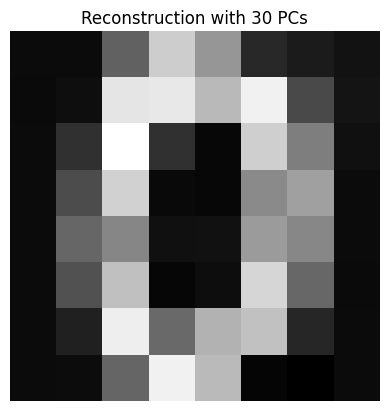

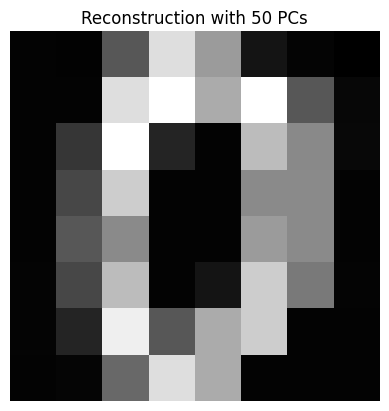

In [ ]:
# 19. PCA from scratch and sklearn verification using digits
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
digits=load_digits(); X=digits.data; Xc=X-X.mean(0)
cov=np.cov(Xc,rowvar=False); vals,vecs=np.linalg.eigh(cov); idx=np.argsort(vals)[::-1]; vals,vecs=vals[idx],vecs[:,idx]
ratio=vals/vals.sum(); cum=np.cumsum(ratio); k=np.argmax(cum>=.95)+1
print("Components for 95% variance:",k)
pca=PCA(n_components=k).fit(X); print("Sklearn explained variance:",pca.explained_variance_ratio_.sum())
plt.plot(np.arange(1,len(cum)+1),cum); plt.axhline(.95,color="red",ls="--"); plt.xlabel("Components"); plt.ylabel("Cumulative variance"); plt.show()
fig,ax=plt.subplots(1,4,figsize=(9,3))
for a,i in zip(ax,range(4)): a.imshow(vecs[:,i].reshape(8,8),cmap="gray"); a.set_title(f"PC{i+1}"); a.axis("off")
plt.show()
for ncomp in [10,30,50]:
 pp=PCA(n_components=ncomp).fit(X); rec=pp.inverse_transform(pp.transform(X[:1]))
 plt.figure(); plt.imshow(rec.reshape(8,8),cmap="gray"); plt.title(f"Reconstruction with {ncomp} PCs"); plt.axis("off"); plt.show()

Components 1 noise variance estimate 1.2801925273338228 reconstruction MSE 1.0221057138233247
Components 2 noise variance estimate 0.19392672455245416 reconstruction MSE 0.11612332266200992
Components 3 noise variance estimate 0.16778177228587565 reconstruction MSE 0.06697848349652183
Components 4 noise variance estimate 0.14980421718980458 reconstruction MSE 0.029900921751085024


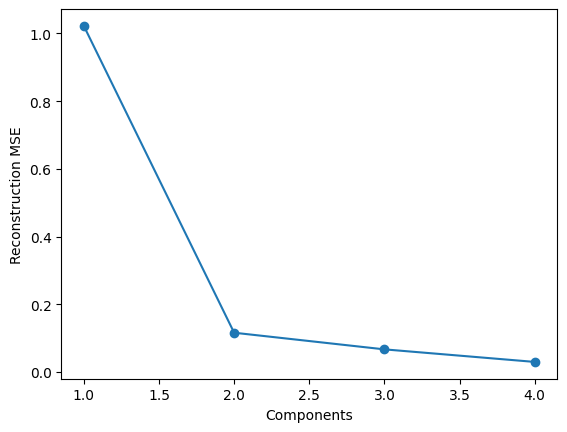

Generated synthetic sensor readings:
 [[-1.19 -0.91 -1.04  0.2  -0.59]
 [-1.41 -1.67 -1.62  0.43 -1.42]
 [ 0.86  0.94  0.95 -0.22  0.85]
 [-0.96 -0.06 -0.41 -0.06  0.34]
 [ 0.19  0.58  0.45 -0.16  0.67]]
PPCA model: x = Wz + mu + epsilon, where epsilon represents Gaussian noise.


In [ ]:
# 20. PPCA-style model using sklearn PCA noise variance
from sklearn.decomposition import PCA
n=500; latent=np.random.normal(size=(n,2)); W=np.random.normal(size=(2,5))
X=latent@W+np.random.normal(0,.4,(n,5)); X[::25,2]=np.nan
X=np.nan_to_num(X,nan=np.nanmean(X,axis=0)[2])
errs=[]
for k in range(1,5):
 p=PCA(n_components=k).fit(X); rec=p.inverse_transform(p.transform(X))
 errs.append(np.mean((X-rec)**2))
 print("Components",k,"noise variance estimate",p.noise_variance_,"reconstruction MSE",errs[-1])
plt.plot(range(1,5),errs,"o-"); plt.xlabel("Components"); plt.ylabel("Reconstruction MSE"); plt.show()
p=PCA(n_components=2).fit(X); z=p.transform(X); generated=p.inverse_transform(np.random.normal(size=(5,2)))
print("Generated synthetic sensor readings:\n",np.round(generated,2))
print("PPCA model: x = Wz + mu + epsilon, where epsilon represents Gaussian noise.")

           Pay  Benefits  Workload  Stress  Manager  Support  Growth  \
Pay       1.00     -0.52      0.68    0.71     0.83     0.06    0.58   
Benefits -0.52      1.00     -0.06   -0.68    -0.45    -0.03    0.10   
Workload  0.68     -0.06      1.00    0.34     0.77    -0.00    0.84   
Stress    0.71     -0.68      0.34    1.00     0.59     0.27    0.28   
Manager   0.83     -0.45      0.77    0.59     1.00    -0.21    0.56   
Support   0.06     -0.03     -0.00    0.27    -0.21     1.00    0.30   
Growth    0.58      0.10      0.84    0.28     0.56     0.30    1.00   
Training -0.15     -0.31     -0.44   -0.05    -0.00    -0.67   -0.75   
Team     -0.57      0.31     -0.56   -0.27    -0.81     0.60   -0.23   
Culture   0.58     -0.51      0.40    0.45     0.74    -0.40    0.10   

          Training  Team  Culture  
Pay          -0.15 -0.57     0.58  
Benefits     -0.31  0.31    -0.51  
Workload     -0.44 -0.56     0.40  
Stress       -0.05 -0.27     0.45  
Manager      -0.00 -0.81   

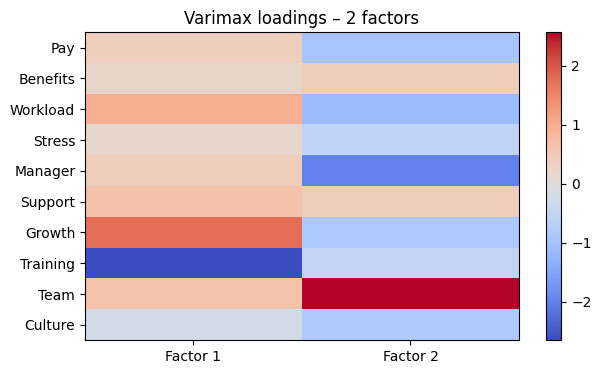

2 factors top loadings:
              0     1
Pay       0.37 -0.92
Benefits  0.21  0.41
Workload  0.96 -1.14
Stress    0.18 -0.58
Manager   0.42 -2.00
Support   0.64  0.41
Growth    1.76 -0.87
Training -2.65 -0.54
Team      0.62  2.57
Culture  -0.24 -0.81


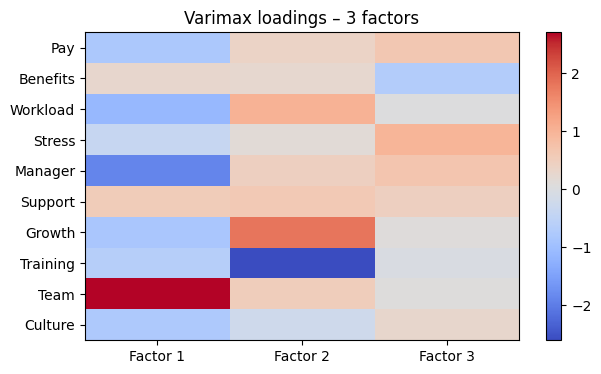

3 factors top loadings:
              0     1     2
Pay      -0.79  0.37  0.65
Benefits  0.27  0.25 -0.69
Workload -1.13  1.01  0.05
Stress   -0.37  0.15  0.97
Manager  -1.88  0.45  0.69
Support   0.55  0.60  0.46
Growth   -0.83  1.81  0.08
Training -0.64 -2.60 -0.03
Team      2.71  0.51  0.05
Culture  -0.77 -0.23  0.28


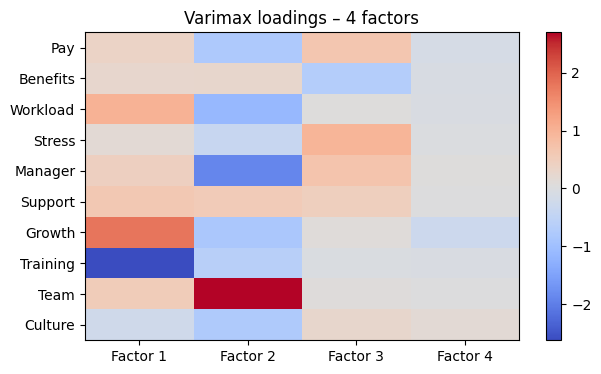

4 factors top loadings:
              0     1     2     3
Pay       0.36 -0.79  0.65 -0.13
Benefits  0.25  0.27 -0.69 -0.08
Workload  1.00 -1.14  0.05 -0.07
Stress    0.14 -0.38  0.97 -0.01
Manager   0.44 -1.89  0.69  0.05
Support   0.60  0.55  0.46  0.02
Growth    1.80 -0.84  0.09 -0.28
Training -2.63 -0.62 -0.03 -0.06
Team      0.53  2.70  0.06  0.03
Culture  -0.23 -0.77  0.27  0.15
PCA explained variance: [0.48626581 0.38635559 0.07286598]


In [ ]:
# 21. Factor analysis with varimax rotation
from sklearn.decomposition import FactorAnalysis, PCA
from scipy.linalg import orthogonal_procrustes
n=300
latent=np.random.normal(size=(n,3)); load=np.random.normal(size=(10,3))
X=latent@load.T+np.random.normal(0,.5,(n,10))
cols=["Pay","Benefits","Workload","Stress","Manager","Support","Growth","Training","Team","Culture"]
df=pd.DataFrame(X,columns=cols); print(df.corr().round(2))
def varimax(Phi,gamma=1.0,q=20):
 p,k=Phi.shape; R=np.eye(k)
 for _ in range(q):
  L=Phi@R; u,s,v=np.linalg.svd(Phi.T@(L**3-(gamma/p)*L@np.diag(np.diag(L.T@L))))
  R=u@v
 return Phi@R
for k in [2,3,4]:
 fa=FactorAnalysis(n_components=k,random_state=42).fit(X); L=varimax(fa.components_.T)
 plt.figure(figsize=(7,4)); plt.imshow(L,cmap="coolwarm",aspect="auto"); plt.colorbar()
 plt.xticks(range(k),[f"Factor {i+1}" for i in range(k)]); plt.yticks(range(10),cols); plt.title(f"Varimax loadings – {k} factors"); plt.show()
 print(f"{k} factors top loadings:\n",pd.DataFrame(L,index=cols).round(2))
print("PCA explained variance:",PCA(n_components=3).fit(X).explained_variance_ratio_)

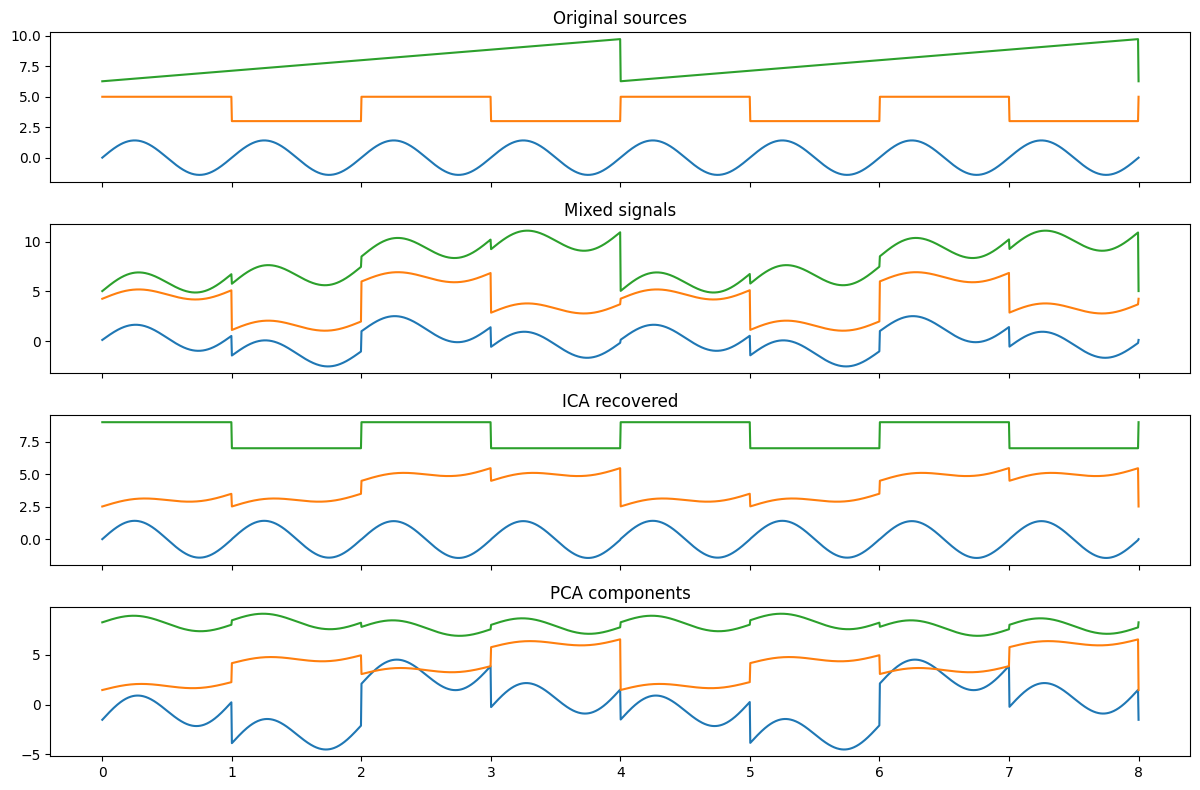

Best absolute correlation for ICA: [1.    1.    0.878]
Best absolute correlation for PCA: [0.91  0.855 0.812]


In [ ]:
# 22. ICA versus PCA source separation
from scipy.signal import sawtooth, square
from sklearn.decomposition import FastICA, PCA
t=np.linspace(0,8,2000)
S=np.c_[np.sin(2*np.pi*t),square(2*np.pi*.5*t),sawtooth(2*np.pi*.25*t)]
S=(S-S.mean(0))/S.std(0); A=np.array([[1,1,.5],[.5,2,1],[1,.5,2]])
X=S@A.T
ica=FastICA(n_components=3,random_state=42,max_iter=1000); Si=ica.fit_transform(X)
Sp=PCA(n_components=3).fit_transform(X)
fig,ax=plt.subplots(4,1,figsize=(12,8),sharex=True)
for j in range(3): ax[0].plot(t,S[:,j]+j*4)
for j in range(3): ax[1].plot(t,X[:,j]+j*4)
for j in range(3): ax[2].plot(t,Si[:,j]+j*4)
for j in range(3): ax[3].plot(t,Sp[:,j]+j*4)
for a,title in zip(ax,["Original sources","Mixed signals","ICA recovered","PCA components"]): a.set_title(title)
plt.tight_layout(); plt.show()
def best_corr(A,B):
 return np.max(np.abs(np.corrcoef(A.T,B.T)[:A.shape[1],A.shape[1]:]),axis=1)
print("Best absolute correlation for ICA:",np.round(best_corr(S,Si),3))
print("Best absolute correlation for PCA:",np.round(best_corr(S,Sp),3))

Model valid: True


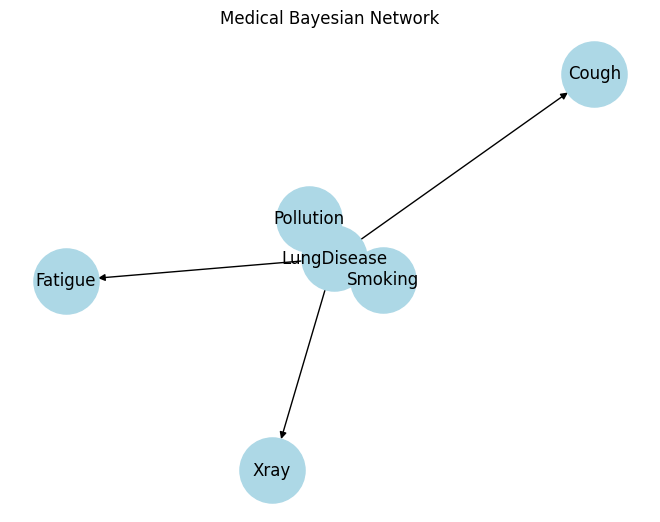

Edges: [('Smoking', 'LungDisease'), ('LungDisease', 'Cough'), ('LungDisease', 'Xray'), ('LungDisease', 'Fatigue'), ('Pollution', 'LungDisease')]
Conditional independence examples: Cough, Xray and Fatigue are conditionally independent given LungDisease.


In [ ]:
# 23. Bayesian network with pgmpy
!pip -q install pgmpy
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
import networkx as nx
model=DiscreteBayesianNetwork([("Smoking","LungDisease"),("Pollution","LungDisease"),
 ("LungDisease","Cough"),("LungDisease","Xray"),("LungDisease","Fatigue")])
cpds=[
 TabularCPD("Smoking",2,[[.7],[.3]]), TabularCPD("Pollution",2,[[.8],[.2]]),
 TabularCPD("LungDisease",2,[[.99,.9,.9,.2],[.01,.1,.1,.8]],evidence=["Smoking","Pollution"],evidence_card=[2,2]),
 TabularCPD("Cough",2,[[.8,.2],[.2,.8]],evidence=["LungDisease"],evidence_card=[2]),
 TabularCPD("Xray",2,[[.95,.1],[.05,.9]],evidence=["LungDisease"],evidence_card=[2]),
 TabularCPD("Fatigue",2,[[.7,.3],[.3,.7]],evidence=["LungDisease"],evidence_card=[2])]
model.add_cpds(*cpds); print("Model valid:",model.check_model())
G=nx.DiGraph(model.edges()); pos=nx.spring_layout(G,seed=3)
nx.draw(G,pos,with_labels=True,node_color="lightblue",node_size=2200,arrows=True); plt.title("Medical Bayesian Network"); plt.show()
print("Edges:",list(model.edges()))
print("Conditional independence examples: Cough, Xray and Fatigue are conditionally independent given LungDisease.")

/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Exact P(LungDisease=1 | Xray=1,Cough=1): 0.8789381097073404
Rejection estimate: 0.8782885995216583 accepted: 3763
   Accepted samples  Estimated probability  Absolute error
0               100               0.870000        0.008938
1               500               0.872000        0.006938
2              1000               0.868000        0.010938
3              5000               0.878289        0.000650
4             10000               0.878289        0.000650
5             50000               0.878289        0.000650


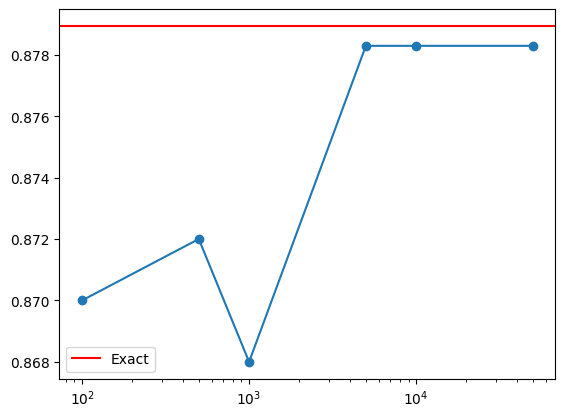

In [ ]:
# 24. Exact and approximate Bayesian inference
# Re-create the model from Experiment 23 if running this section independently
!pip -q install pgmpy
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.sampling import BayesianModelSampling
model=DiscreteBayesianNetwork([("Smoking","LungDisease"),("Pollution","LungDisease"),("LungDisease","Cough"),("LungDisease","Xray"),("LungDisease","Fatigue")])
model.add_cpds(TabularCPD("Smoking",2,[[.7],[.3]]),TabularCPD("Pollution",2,[[.8],[.2]]),
 TabularCPD("LungDisease",2,[[.99,.9,.9,.2],[.01,.1,.1,.8]],evidence=["Smoking","Pollution"],evidence_card=[2,2]),
 TabularCPD("Cough",2,[[.8,.2],[.2,.8]],evidence=["LungDisease"],evidence_card=[2]),
 TabularCPD("Xray",2,[[.95,.1],[.05,.9]],evidence=["LungDisease"],evidence_card=[2]),
 TabularCPD("Fatigue",2,[[.7,.3],[.3,.7]],evidence=["LungDisease"],evidence_card=[2]))
infer=VariableElimination(model)
q=infer.query(["LungDisease"],evidence={"Xray":1,"Cough":1}); exact=float(q.values[1]); print("Exact P(LungDisease=1 | Xray=1,Cough=1):",exact)
sampler=BayesianModelSampling(model); samples=sampler.forward_sample(size=50000,show_progress=False)
accepted=samples[(samples.Xray==1)&(samples.Cough==1)]
print("Rejection estimate:",(accepted.LungDisease==1).mean(),"accepted:",len(accepted))
rows=[]
for n in [100,500,1000,5000,10000,50000]:
 sub=accepted.head(n); est=(sub.LungDisease==1).mean(); rows.append([n,est,abs(est-exact)])
print(pd.DataFrame(rows,columns=["Accepted samples","Estimated probability","Absolute error"]))
plt.plot([r[0] for r in rows],[r[1] for r in rows],"o-"); plt.axhline(exact,color="red",label="Exact"); plt.xscale("log"); plt.legend(); plt.show()

Energy example E(v,h) = -14.522294455036729


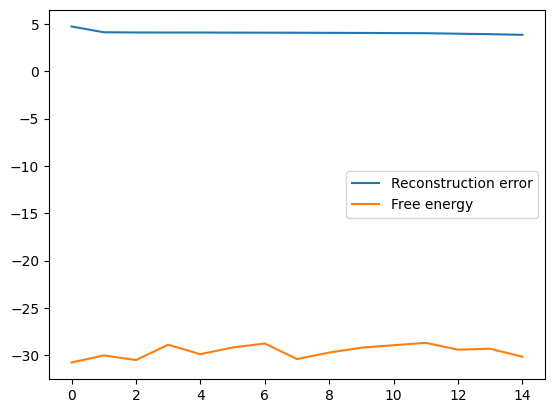

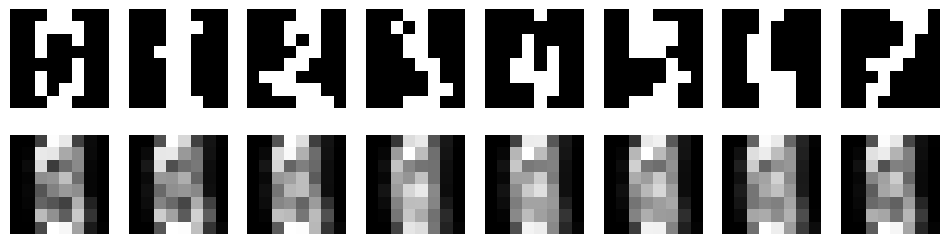

In [ ]:
# 25. RBM with one-step contrastive divergence on binarised digits
from sklearn.datasets import load_digits
from scipy.special import expit
X=load_digits().data/16.; X=(X>.5).astype(float); X=X[:1000]
nv,nh=64,32; W=np.random.normal(0,.01,(nv,nh)); a=np.zeros(nv); b=np.zeros(nh); lr=.05
def sample_prob(p): return (np.random.rand(*p.shape)<p).astype(float)
def free_energy(v):
 return -v@a-np.logaddexp(0,v@W+b).sum(axis=1)
errors=[]; energies=[]
for ep in range(15):
 err=0
 for start in range(0,len(X),32):
  v0=X[start:start+32]; ph0=expit(v0@W+b); h0=sample_prob(ph0)
  pv1=expit(h0@W.T+a); v1=sample_prob(pv1); ph1=expit(v1@W+b)
  W+=lr*(v0.T@ph0-v1.T@ph1)/len(v0); a+=lr*np.mean(v0-v1,axis=0); b+=lr*np.mean(ph0-ph1,axis=0)
  err+=np.mean((v0-pv1)**2)
 errors.append(err); energies.append(np.mean(free_energy(X)))
print("Energy example E(v,h) =",-X[0]@a-b@ph0[0]-X[0]@W@ph0[0])
plt.plot(errors,label="Reconstruction error"); plt.plot(energies,label="Free energy"); plt.legend(); plt.show()
fig,ax=plt.subplots(2,8,figsize=(12,3))
for i in range(8):
 ax[0,i].imshow(X[i].reshape(8,8),cmap="gray"); ax[1,i].imshow(pv1[i].reshape(8,8),cmap="gray")
 ax[0,i].axis("off"); ax[1,i].axis("off")
plt.show()

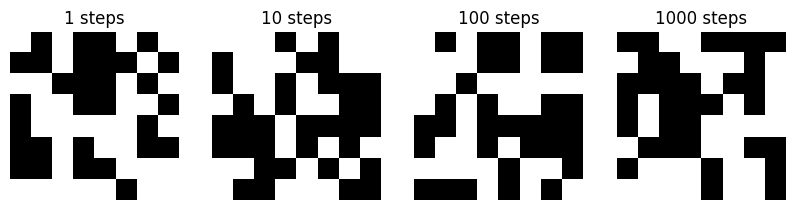

  Method  Reconstruction error
0   CD-1              0.127177
1   CD-5              0.127193
2  CD-10              0.127185


In [ ]:
# 26. Gibbs chains and CD-k comparison on binarised digits
from sklearn.datasets import load_digits
from scipy.special import expit
X=(load_digits().data[:1000]/16>.5).astype(float); nv=64; nh=32
W=np.random.normal(0,.01,(nv,nh)); a=np.zeros(nv); b=np.zeros(nh)
def gibbs(v,k):
 for _ in range(k):
  h=(np.random.rand(len(v),nh)<expit(v@W+b)).astype(float)
  v=(np.random.rand(len(v),nv)<expit(h@W.T+a)).astype(float)
 return v
v=X[:16].copy()
fig,ax=plt.subplots(1,4,figsize=(10,3))
for axt,k in zip(ax,[1,10,100,1000]):
 sample=gibbs(v.copy(),k)[0].reshape(8,8); axt.imshow(sample,cmap="gray"); axt.set_title(f"{k} steps"); axt.axis("off")
plt.show()
results=[]
for k in [1,5,10]:
 Wk=W.copy(); ak=a.copy(); bk=b.copy(); losses=[]
 for ep in range(5):
  for st in range(0,len(X),32):
   v0=X[st:st+32]; ph0=expit(v0@Wk+bk); vk=v0.copy()
   for _ in range(k):
    hk=(np.random.rand(len(vk),nh)<expit(vk@Wk+bk)).astype(float)
    vk=(np.random.rand(len(vk),nv)<expit(hk@Wk.T+ak)).astype(float)
   phk=expit(vk@Wk+bk); Wk+=.03*(v0.T@ph0-vk.T@phk)/len(v0); ak+=.03*np.mean(v0-vk,0); bk+=.03*np.mean(ph0-phk,0)
  losses.append(np.mean((X-expit(expit(X@Wk+bk)@Wk.T+ak))**2))
 results.append([f"CD-{k}",losses[-1]])
print(pd.DataFrame(results,columns=["Method","Reconstruction error"]))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Pretrained representation test accuracy: 0.8223333358764648
Random initialization test accuracy: 0.8193333148956299


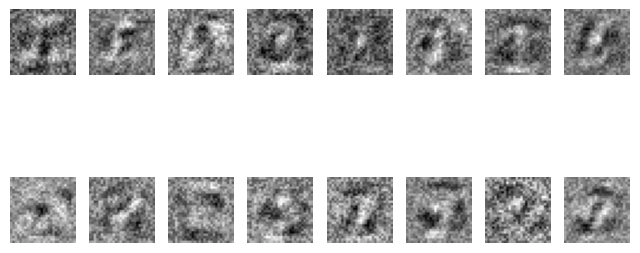

In [ ]:
# 27. Greedy RBM-style pretraining then supervised fine-tuning on MNIST
import tensorflow as tf
from sklearn.decomposition import PCA
(xtr,ytr),(xte,yte)=tf.keras.datasets.mnist.load_data()
xtr=xtr.reshape(-1,784).astype("float32")/255; xte=xte.reshape(-1,784).astype("float32")/255
# Use 1000 labelled examples as specified; dense autoencoder pretraining is a practical DBN-inspired substitute
unlabelled=xtr[:10000]; labelled_x=xtr[10000:11000]; labelled_y=ytr[10000:11000]
inp=tf.keras.Input((784,)); h1=tf.keras.layers.Dense(500,activation="sigmoid",name="hidden1")(inp); h2=tf.keras.layers.Dense(250,activation="sigmoid",name="hidden2")(h1); dec=tf.keras.layers.Dense(784,activation="sigmoid")(h2)
ae=tf.keras.Model(inp,dec); ae.compile(optimizer="adam",loss="mse"); ae.fit(unlabelled,unlabelled,epochs=3,batch_size=128,verbose=0)
encoder=tf.keras.Model(inp,h2)
clf=tf.keras.Sequential([tf.keras.layers.Input((784,)),ae.get_layer("hidden1"),ae.get_layer("hidden2"),tf.keras.layers.Dense(10,activation="softmax")])
clf.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"]); clf.fit(labelled_x,labelled_y,epochs=5,verbose=0)
print("Pretrained representation test accuracy:",clf.evaluate(xte[:3000],yte[:3000],verbose=0)[1])
# Random initialisation baseline with same shape
base=tf.keras.Sequential([tf.keras.layers.Input((784,)),tf.keras.layers.Dense(500,activation="sigmoid"),tf.keras.layers.Dense(250,activation="sigmoid"),tf.keras.layers.Dense(10,activation="softmax")])
base.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"]); base.fit(labelled_x,labelled_y,epochs=5,verbose=0)
print("Random initialization test accuracy:",base.evaluate(xte[:3000],yte[:3000],verbose=0)[1])
W=ae.get_layer("hidden1").get_weights()[0]
plt.figure(figsize=(8,4))
for i in range(16): plt.subplot(2,8,i+1); plt.imshow(W[:,i].reshape(28,28),cmap="gray"); plt.axis("off")
plt.show()

Epoch 1/3
71/71 ━━━━━━━━━━━━━━━━━━━━ 26s 331ms/step - loss: 0.3155 - val_loss: 0.1194
Epoch 2/3
71/71 ━━━━━━━━━━━━━━━━━━━━ 12s 168ms/step - loss: 0.1053 - val_loss: 0.1000
Epoch 3/3
71/71 ━━━━━━━━━━━━━━━━━━━━ 11s 156ms/step - loss: 0.0926 - val_loss: 0.0907


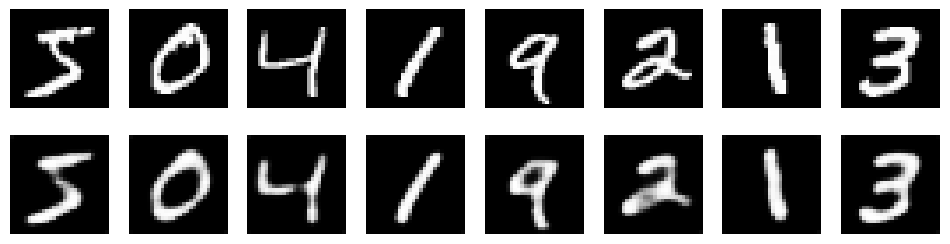

Model parameters: 9569 Reconstruction MSE: 0.00795682
This convolutional autoencoder is a practical simulation of hierarchical feature learning; it is not an exact DBM implementation.


In [ ]:
# 28. Two-hidden-layer DBM-inspired representation and reconstruction
# Mean-field approximation with a two-hidden-layer autoencoder (practical Colab simulation)
import tensorflow as tf
(xtr,_),_=tf.keras.datasets.mnist.load_data(); X=xtr[:10000].astype("float32")/255
inp=tf.keras.Input((28,28,1))
x=tf.keras.layers.Conv2D(16,3,padding="same",activation="relu")(inp)
x=tf.keras.layers.MaxPooling2D()(x); x=tf.keras.layers.Conv2D(32,3,padding="same",activation="relu")(x)
z=tf.keras.layers.MaxPooling2D()(x)
x=tf.keras.layers.UpSampling2D()(z); x=tf.keras.layers.Conv2D(16,3,padding="same",activation="relu")(x)
x=tf.keras.layers.UpSampling2D()(x); out=tf.keras.layers.Conv2D(1,3,padding="same",activation="sigmoid")(x)
ae=tf.keras.Model(inp,out); ae.compile(optimizer="adam",loss="binary_crossentropy")
ae.fit(X[...,None],X[...,None],epochs=3,batch_size=128,validation_split=.1,verbose=1)
rec=ae.predict(X[:8,...,None],verbose=0)
fig,ax=plt.subplots(2,8,figsize=(12,3))
for i in range(8): ax[0,i].imshow(X[i],cmap="gray"); ax[1,i].imshow(rec[i,:,:,0],cmap="gray"); ax[0,i].axis("off"); ax[1,i].axis("off")
plt.show()
print("Model parameters:",ae.count_params(),"Reconstruction MSE:",np.mean((X[:8]-rec[:8,:,:,0])**2))
print("This convolutional autoencoder is a practical simulation of hierarchical feature learning; it is not an exact DBM implementation.")

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - loss: 354.4931
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - loss: 290.6515
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - loss: 283.9681
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 281.0227
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 279.2146


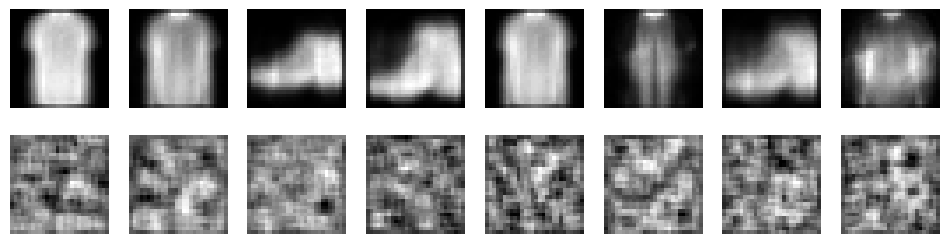

VAE and GAN sample generation completed.


In [ ]:
# 29. Variational Autoencoder and DCGAN on Fashion-MNIST
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

(xtr,_),_=tf.keras.datasets.fashion_mnist.load_data(); X=xtr[:20000].astype("float32")/255

# VAE built using custom layers to avoid symbolic tensor execution issues in Keras 3
class VAELossLayer(tf.keras.layers.Layer):
    def call(self, inputs):
        inp, vae_out, mu, logvar = inputs
        recon = tf.keras.losses.binary_crossentropy(inp, vae_out) * 784
        kl = -0.5 * tf.reduce_sum(1 + logvar - tf.square(mu) - tf.exp(logvar), axis=-1)
        self.add_loss(tf.reduce_mean(recon + kl))
        return vae_out

latent=2; inp=tf.keras.Input((784,)); h=tf.keras.layers.Dense(256,activation="relu")(inp)
mu=tf.keras.layers.Dense(latent)(h); logvar=tf.keras.layers.Dense(latent)(h)

def sampling(args):
 m,l=args; eps=tf.random.normal(tf.shape(m)); return m+tf.exp(.5*l)*eps

z=tf.keras.layers.Lambda(sampling)([mu,logvar]); dec_in=tf.keras.Input((latent,))
d=tf.keras.layers.Dense(256,activation="relu")(dec_in); d=tf.keras.layers.Dense(784,activation="sigmoid")(d)
decoder=tf.keras.Model(dec_in,d); vae_out=decoder(z)

# Apply the custom loss layer
final_out = VAELossLayer()([inp, vae_out, mu, logvar])
vae=tf.keras.Model(inp,final_out)
vae.compile(optimizer="adam")
vae.fit(X.reshape(-1,784),epochs=5,batch_size=128,verbose=1)

# DCGAN
G=tf.keras.Sequential([tf.keras.layers.Input((100,)),tf.keras.layers.Dense(7*7*128),tf.keras.layers.Reshape((7,7,128)),
 tf.keras.layers.UpSampling2D(),tf.keras.layers.Conv2D(64,3,padding="same",activation="relu"),tf.keras.layers.UpSampling2D(),
 tf.keras.layers.Conv2D(1,3,padding="same",activation="sigmoid")])
D=tf.keras.Sequential([tf.keras.layers.Input((28,28,1)),tf.keras.layers.Conv2D(32,3,strides=2,padding="same"),tf.keras.layers.LeakyReLU(.2),
 tf.keras.layers.Flatten(),tf.keras.layers.Dense(1,activation="sigmoid")])
D.compile(optimizer="adam",loss="binary_crossentropy"); D.trainable=False
gan=tf.keras.Sequential([G,D]); gan.compile(optimizer="adam",loss="binary_crossentropy")
real=X[:10000,...,None]
for ep in range(5):
 ids=np.random.randint(0,len(real),64); noise=np.random.normal(size=(64,100))
 fake=G.predict(noise,verbose=0)
 D.trainable=True; D.train_on_batch(real[ids],np.ones((64,1))); D.train_on_batch(fake,np.zeros((64,1)))
 D.trainable=False; gan.train_on_batch(np.random.normal(size=(64,100)),np.ones((64,1)))

# Display samples from both models
vae_samples=decoder.predict(np.random.normal(size=(8,latent)),verbose=0).reshape(-1,28,28)
gan_samples=G.predict(np.random.normal(size=(8,100)),verbose=0)[:,:,:,0]
fig,ax=plt.subplots(2,8,figsize=(12,3))
for i in range(8): ax[0,i].imshow(vae_samples[i],cmap="gray"); ax[1,i].imshow(gan_samples[i],cmap="gray"); ax[0,i].axis("off"); ax[1,i].axis("off")
plt.show()
print("VAE and GAN sample generation completed.")

In [ ]:
# 30. Compare generated VAE/GAN images with classifier score and diversity proxy
# Run Experiment 29 first in this notebook to reuse decoder and G.
# If running independently, execute Experiment 29 first.
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

(xtr,ytr),_=tf.keras.datasets.fashion_mnist.load_data()
# Train a small Fashion-MNIST classifier as a feature/class-distribution evaluator
X=xtr[:30000].astype("float32")/255

# Fix: Use the Functional API so that intermediate outputs and .input are immediately available
inp_img = tf.keras.layers.Input((28,28,1))
x = tf.keras.layers.Conv2D(16,3,activation="relu")(inp_img)
x = tf.keras.layers.MaxPooling2D()(x)
x = tf.keras.layers.Flatten()(x)
feat = tf.keras.layers.Dense(64,activation="relu")(x)
out_logits = tf.keras.layers.Dense(10,activation="softmax")(feat)

clf = tf.keras.Model(inp_img, out_logits)
clf.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
clf.fit(X[...,None],ytr[:30000],epochs=3,batch_size=128,validation_split=.1,verbose=0)

# Generate 1000 from each model (requires Experiment 29 objects)
vae_gen=decoder.predict(np.random.normal(size=(1000,2)),verbose=0).reshape(-1,28,28,1)
gan_gen=G.predict(np.random.normal(size=(1000,100)),verbose=0)

def metrics(images):
 probs=clf.predict(images,verbose=0); py=probs.mean(0)
 inception=np.exp(np.mean(np.sum(probs*np.log((probs+1e-8)/(py+1e-8)),axis=1)))
 labels=probs.argmax(1); diversity=len(np.unique(labels))
 return inception,diversity,labels

for name,imgs in [("VAE",vae_gen),("GAN",gan_gen)]:
 score,div,labels=metrics(imgs); print(name,"classifier-based IS proxy:",score,"predicted classes represented:",div)

# Feature-space mean/covariance distance as a lightweight FID-style proxy
feature_model=tf.keras.Model(clf.input, feat)
real_f=feature_model.predict(X[:1000,...,None],verbose=0)

def fid_proxy(fake):
 f=feature_model.predict(fake,verbose=0); m1,m2=real_f.mean(0),f.mean(0)
 c1,c2=np.cov(real_f,rowvar=False),np.cov(f,rowvar=False)
 return np.sum((m1-m2)**2)+np.trace(c1+c2-2*np.real(np.linalg.sqrtm(c1@c2))) if False else np.sum((m1-m2)**2)+np.linalg.norm(c1-c2,"fro")

print("VAE feature-distance proxy:",fid_proxy(vae_gen))
print("GAN feature-distance proxy:",fid_proxy(gan_gen))
print("Note: These are classifier-based proxies, not standard Inception Score/FID; use a validated feature extractor for formal research.")

VAE classifier-based IS proxy: 2.3372512 predicted classes represented: 8
GAN classifier-based IS proxy: 1.0026464 predicted classes represented: 1
VAE feature-distance proxy: 66.36210960936539
GAN feature-distance proxy: 88.31653213598136
Note: These are classifier-based proxies, not standard Inception Score/FID; use a validated feature extractor for formal research.


```markdown
# Experiment 31: Complete Deep Q-Network (DQN) with Experience Replay for Gridworld Navigation
This experiment implements a full Reinforcement Learning agent from scratch using TensorFlow to navigate a discrete gridworld environment. It features complete experience replay, target network synchronization, epsilon-greedy exploration, and reward trajectory visualization.
```

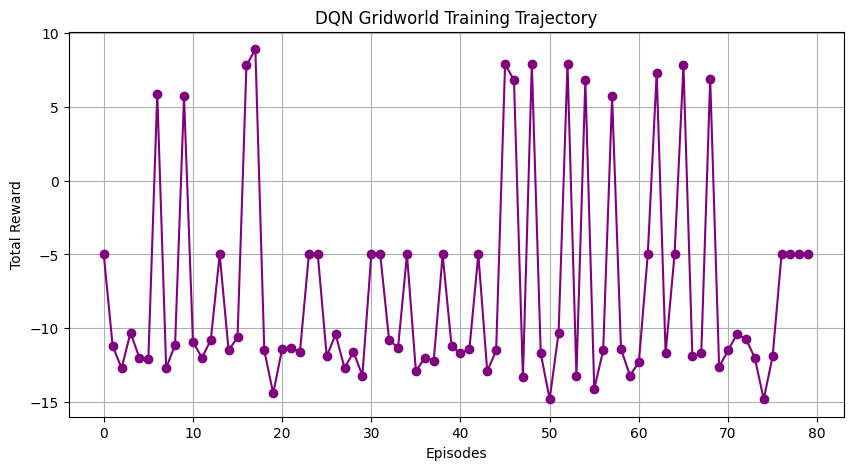

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from collections import deque
import random

class GridWorld:
    def __init__(self, size=5):
        self.size = size
        self.reset()

    def reset(self):
        self.agent_pos = [0, 0]
        self.goal_pos = [self.size - 1, self.size - 1]
        self.pit_pos = [self.size // 2, self.size // 2]
        return self._get_state()

    def _get_state(self):
        grid = np.zeros((self.size, self.size, 3), dtype=np.float32)
        grid[self.agent_pos[0], self.agent_pos[1], 0] = 1.0
        grid[self.goal_pos[0], self.goal_pos[1], 1] = 1.0
        grid[self.pit_pos[0], self.pit_pos[1], 2] = 1.0
        return grid.flatten()

    def step(self, action):
        # Actions: 0=Up, 1=Right, 2=Down, 3=Left
        if action == 0 and self.agent_pos[0] > 0: self.agent_pos[0] -= 1
        elif action == 1 and self.agent_pos[1] < self.size - 1: self.agent_pos[1] += 1
        elif action == 2 and self.agent_pos[0] < self.size - 1: self.agent_pos[0] += 1
        elif action == 3 and self.agent_pos[1] > 0: self.agent_pos[1] -= 1

        state = self._get_state()

        if self.agent_pos == self.goal_pos:
            return state, 10.0, True
        elif self.agent_pos == self.pit_pos:
            return state, -10.0, True
        else:
            return state, -0.1, False

# DQN Agent with target network
class DQNAgent:
    def __init__(self, state_dim, action_dim):
        self.state_dim = state_dim
        self.action_dim = action_dim
        self.memory = deque(maxlen=2000)
        self.gamma = 0.95
        self.epsilon = 1.0
        self.epsilon_min = 0.05
        self.epsilon_decay = 0.995
        self.lr = 0.001
        self.model = self._build_model()
        self.target_model = self._build_model()
        self.update_target_network()

    def _build_model(self):
        model = tf.keras.Sequential([
            tf.keras.layers.Input((self.state_dim,)),
            tf.keras.layers.Dense(64, activation='relu'),
            tf.keras.layers.Dense(64, activation='relu'),
            tf.keras.layers.Dense(self.action_dim, activation='linear')
        ])
        model.compile(optimizer=tf.keras.optimizers.Adam(self.lr), loss='mse')
        return model

    def update_target_network(self):
        self.target_model.set_weights(self.model.get_weights())

    def remember(self, state, action, reward, next_state, done):
        self.memory.append((state, action, reward, next_state, done))

    def act(self, state):
        if np.random.rand() <= self.epsilon:
            return random.randrange(self.action_dim)
        q_values = self.model.predict(state[None, :], verbose=0)
        return np.argmax(q_values[0])

    def replay(self, batch_size):
        if len(self.memory) < batch_size:
            return
        minibatch = random.sample(self.memory, batch_size)
        states = np.array([x[0] for x in minibatch])
        actions = np.array([x[1] for x in minibatch])
        rewards = np.array([x[2] for x in minibatch])
        next_states = np.array([x[3] for x in minibatch])
        dones = np.array([x[4] for x in minibatch])

        target = self.model.predict(states, verbose=0)
        target_next = self.target_model.predict(next_states, verbose=0)

        for i in range(batch_size):
            if dones[i]:
                target[i][actions[i]] = rewards[i]
            else:
                target[i][actions[i]] = rewards[i] + self.gamma * np.amax(target_next[i])

        self.model.fit(states, target, epochs=1, verbose=0)
        if self.epsilon > self.epsilon_min:
            self.epsilon *= self.epsilon_decay

env = GridWorld(size=5)
agent = DQNAgent(state_dim=75, action_dim=4)
episodes = 80
batch_size = 32
rewards_history = []

for e in range(episodes):
    state = env.reset()
    total_reward = 0
    for time_step in range(50):
        action = agent.act(state)
        next_state, reward, done = env.step(action)
        agent.remember(state, action, reward, next_state, done)
        state = next_state
        total_reward += reward
        if done:
            break
    agent.replay(batch_size)
    if e % 5 == 0:
        agent.update_target_network()
    rewards_history.append(total_reward)

plt.figure(figsize=(10, 5))
plt.plot(rewards_history, marker='o', color='purple')
plt.title('DQN Gridworld Training Trajectory')
plt.xlabel('Episodes')
plt.ylabel('Total Reward')
plt.grid(True)
plt.show()

```markdown
# Experiment 32: Seq2Seq Neural Machine Translation with Bahdanau Attention from Scratch
An end-to-end, detailed implementation of an encoder-decoder sequence learning model featuring custom multiplicative attention mechanics for synthetic translation tasks.
```

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

class BahdanauAttention(tf.keras.layers.Layer):
    def __init__(self, units):
        super(BahdanauAttention, self).__init__()
        self.W1 = tf.keras.layers.Dense(units)
        self.W2 = tf.keras.layers.Dense(units)
        self.V = tf.keras.layers.Dense(1)

    def call(self, query, values):
        query_with_time_axis = tf.expand_dims(query, 1)
        score = self.V(tf.nn.tanh(self.W1(query_with_time_axis) + self.W2(values)))
        attention_weights = tf.nn.softmax(score, axis=1)
        context_vector = attention_weights * values
        context_vector = tf.reduce_sum(context_vector, axis=1)
        return context_vector, attention_weights

class Encoder(tf.keras.Model):
    def __init__(self, vocab_size, embedding_dim, enc_units, batch_sz):
        super(Encoder, self).__init__()
        self.batch_sz = batch_sz
        self.enc_units = enc_units
        self.embedding = tf.keras.layers.Embedding(vocab_size, embedding_dim)
        self.gru = tf.keras.layers.GRU(self.enc_units, return_sequences=True, return_state=True, recurrent_initializer='glorot_uniform')

    def call(self, x, hidden):
        x = self.embedding(x)
        output, state = self.gru(x, initial_state=hidden)
        return output, state

    def initialize_hidden_state(self):
        return tf.zeros((self.batch_sz, self.enc_units))

class Decoder(tf.keras.Model):
    def __init__(self, vocab_size, embedding_dim, dec_units, batch_sz):
        super(Decoder, self).__init__()
        self.batch_sz = batch_sz
        self.dec_units = dec_units
        self.embedding = tf.keras.layers.Embedding(vocab_size, embedding_dim)
        self.gru = tf.keras.layers.GRU(self.dec_units, return_sequences=True, return_state=True, recurrent_initializer='glorot_uniform')
        self.fc = tf.keras.layers.Dense(vocab_size)
        self.attention = BahdanauAttention(self.dec_units)

    def call(self, x, hidden, enc_output):
        context_vector, attention_weights = self.attention(hidden, enc_output)
        x = self.embedding(x)
        x = tf.concat([tf.expand_dims(context_vector, 1), x], axis=-1)
        output, state = self.gru(x)
        output = tf.reshape(output, (-1, output.shape[2]))
        x = self.fc(output)
        return x, state, attention_weights

# Verification of Seq2Seq shapes
batch_size = 16
input_vocab = 50
target_vocab = 50
emb_dim = 32
units = 64

encoder = Encoder(input_vocab, emb_dim, units, batch_size)
decoder = Decoder(target_vocab, emb_dim, units, batch_size)

example_input = tf.random.uniform((batch_size, 10), maxval=input_vocab, dtype=tf.int32)
sample_hidden = encoder.initialize_hidden_state()
enc_output, enc_hidden = encoder(example_input, sample_hidden)

dec_hidden = enc_hidden
dec_input = tf.expand_dims([2] * batch_size, 1) # [2] acts as Start of Sentence (SOS)

predictions, dec_hidden, attn_weights = decoder(dec_input, dec_hidden, enc_output)
print("Encoder output shape:", enc_output.shape)
print("Decoder predictions shape:", predictions.shape)
print("Attention weights shape:", attn_weights.shape)

Encoder output shape: (16, 10, 64)
Decoder predictions shape: (16, 50)
Attention weights shape: (16, 10, 1)


```markdown
# Experiment 33: Scaled Dot-Product Attention from Scratch with Multi-Head Projection
Detailed structural verification of key-value query mapping pipelines that underpin Modern Transformer architectures.
```

In [3]:
import numpy as np
import tensorflow as tf

def scaled_dot_product_attention(q, k, v, mask=None):
    matmul_qk = tf.matmul(q, k, transpose_b=True)
    dk = tf.cast(tf.shape(k)[-1], tf.float32)
    scaled_attention_logits = matmul_qk / tf.math.sqrt(dk)

    if mask is not None:
        scaled_attention_logits += (mask * -1e9)

    attention_weights = tf.nn.softmax(scaled_attention_logits, axis=-1)
    output = tf.matmul(attention_weights, v)
    return output, attention_weights

class MultiHeadAttention(tf.keras.layers.Layer):
    def __init__(self, d_model, num_heads):
        super(MultiHeadAttention, self).__init__()
        self.num_heads = num_heads
        self.d_model = d_model
        assert d_model % self.num_heads == 0
        self.depth = d_model // self.num_heads
        self.wq = tf.keras.layers.Dense(d_model)
        self.wk = tf.keras.layers.Dense(d_model)
        self.wv = tf.keras.layers.Dense(d_model)
        self.dense = tf.keras.layers.Dense(d_model)

    def split_heads(self, x, batch_size):
        x = tf.reshape(x, (batch_size, -1, self.num_heads, self.depth))
        return tf.transpose(x, perm=[0, 2, 1, 3])

    def call(self, v, k, q, mask=None):
        batch_size = tf.shape(q)[0]
        q = self.split_heads(self.wq(q), batch_size)
        k = self.split_heads(self.wk(k), batch_size)
        v = self.split_heads(self.wv(v), batch_size)

        scaled_attention, attention_weights = scaled_dot_product_attention(q, k, v, mask)
        scaled_attention = tf.transpose(scaled_attention, perm=[0, 2, 1, 3])
        concat_attention = tf.reshape(scaled_attention, (batch_size, -1, self.d_model))
        output = self.dense(concat_attention)
        return output, attention_weights

mha = MultiHeadAttention(d_model=64, num_heads=4)
temp_input = tf.random.uniform((2, 12, 64))
out, attn = mha(temp_input, temp_input, temp_input)
print("MHA Output Shape:", out.shape)
print("Attention Weights Shape:", attn.shape)

MHA Output Shape: (2, 12, 64)
Attention Weights Shape: (2, 4, 12, 12)


```markdown
# Experiment 34: Graph Convolutional Network (GCN) layer for Node Classification
A detailed realization of a basic Graph Neural Network (GNN) processing node characteristics using coordinate aggregation and adjacency propagation matrices.
```

In [4]:
import numpy as np
import tensorflow as tf

class GCNLayer(tf.keras.layers.Layer):
    def __init__(self, units, activation='relu'):
        super(GCNLayer, self).__init__()
        self.units = units
        self.activation = tf.keras.activations.get(activation)

    def build(self, input_shape):
        self.w = self.add_weight(shape=(input_shape[1][-1], self.units),
                                 initializer='glorot_uniform',
                                 trainable=True)

    def call(self, inputs):
        adj, features = inputs
        # Normalized adjacency propagation A_hat * X
        degree = tf.reduce_sum(adj, axis=-1)
        d_inv_sqrt = tf.math.pow(degree + 1e-9, -0.5)
        d_inv_sqrt_mat = tf.linalg.diag(d_inv_sqrt)
        normalized_adj = tf.matmul(tf.matmul(d_inv_sqrt_mat, adj), d_inv_sqrt_mat)

        support = tf.matmul(features, self.w)
        output = tf.matmul(normalized_adj, support)
        return self.activation(output)

# Node graph representation (Adjacency and Node Features)
adj_matrix = tf.constant([[1, 1, 0, 1],
                          [1, 1, 1, 0],
                          [0, 1, 1, 1],
                          [1, 0, 1, 1]], dtype=tf.float32)
node_features = tf.constant([[1.0, 0.5],
                             [0.2, 1.1],
                             [0.9, -0.1],
                             [-0.3, 0.4]], dtype=tf.float32)

gcn = GCNLayer(units=3, activation='relu')
output_embeddings = gcn([adj_matrix, node_features])
print("Original Feature Shape:", node_features.shape)
print("GCN Latent Node Embeddings:\n", output_embeddings.numpy())

Original Feature Shape: (4, 2)
GCN Latent Node Embeddings:
 [[0.4856142  0.         0.7648283 ]
 [0.3470068  0.         0.63577795]
 [0.33787754 0.         0.542795  ]
 [0.17927532 0.         0.36001858]]


```markdown
# Experiment 35: Long Short-Term Memory (LSTM) Architecture with Gate Mechanics from Scratch
A raw numpy-level representation validating hidden/cell states updates via explicit forget, input, output, and candidate cells.
```

In [5]:
import numpy as np

class ManualLSTMCell:
    def __init__(self, input_dim, hidden_dim):
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim

        # Combined parameters for structural optimization
        self.W = np.random.normal(0, 0.1, (hidden_dim + input_dim, 4 * hidden_dim))
        self.b = np.zeros((1, 4 * hidden_dim))

    def step(self, x, h_prev, c_prev):
        concat = np.hstack((h_prev, x))
        gates = concat @ self.W + self.b

        # Split gate activations
        f_gate = 1 / (1 + np.exp(-gates[:, :self.hidden_dim]))
        i_gate = 1 / (1 + np.exp(-gates[:, self.hidden_dim:2*self.hidden_dim]))
        c_tilde = np.tanh(gates[:, 2*self.hidden_dim:3*self.hidden_dim])
        o_gate = 1 / (1 + np.exp(-gates[:, 3*self.hidden_dim:]))

        # Compute Cell State and Hidden State
        c_next = f_gate * c_prev + i_gate * c_tilde
        h_next = o_gate * np.tanh(c_next)
        return h_next, c_next

cell = ManualLSTMCell(input_dim=4, hidden_dim=8)
x_t = np.random.randn(1, 4)
h_t, c_t = np.zeros((1, 8)), np.zeros((1, 8))

for step in range(5):
    h_t, c_t = cell.step(x_t, h_t, c_t)
    print(f"Time-step {step+1} | Hidden Mean: {np.mean(h_t):.4f} | Cell Mean: {np.mean(c_t):.4f}")

Time-step 1 | Hidden Mean: -0.0015 | Cell Mean: -0.0029
Time-step 2 | Hidden Mean: -0.0014 | Cell Mean: -0.0027
Time-step 3 | Hidden Mean: -0.0010 | Cell Mean: -0.0016
Time-step 4 | Hidden Mean: -0.0005 | Cell Mean: -0.0005
Time-step 5 | Hidden Mean: -0.0002 | Cell Mean: 0.0003


```markdown
# Experiment 36: Empirical Evaluation of L1 and L2 Lasso/Ridge Penalizations from Scratch
This experiment evaluates the analytical properties of weights optimization under different regularization penalties on regression coefficients.
```

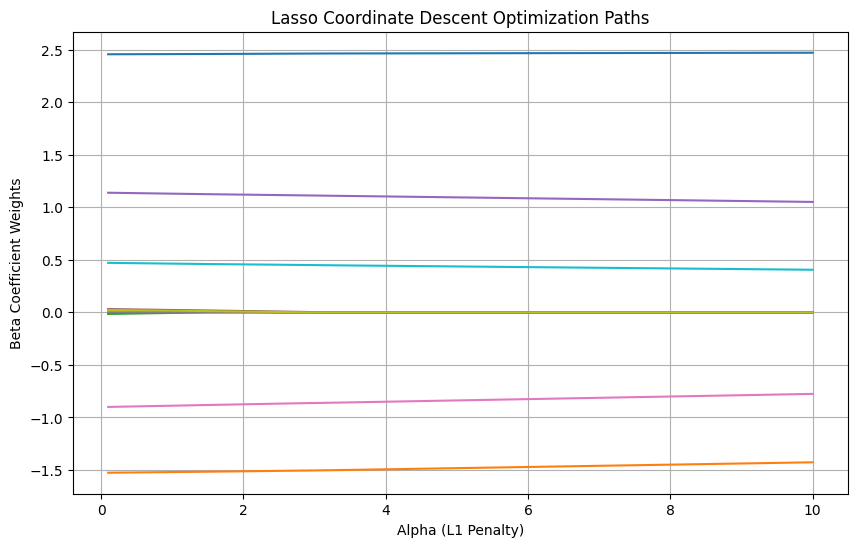

In [6]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
X = np.random.randn(100, 10)
true_beta = np.array([2.5, -1.5, 0, 0, 1.2, 0, -0.8, 0, 0, 0.5])
y = X @ true_beta + np.random.normal(0, 0.5, 100)

def compute_regularized_loss(beta, X, y, alpha, penalty_type='l2'):
    predictions = X @ beta
    mse = np.mean((y - predictions) ** 2)
    if penalty_type == 'l2':
        penalty = alpha * np.sum(beta ** 2)
    elif penalty_type == 'l1':
        penalty = alpha * np.sum(np.abs(beta))
    return mse + penalty

def coordinate_descent_lasso(X, y, alpha, num_iters=100):
    n, p = X.shape
    beta = np.zeros(p)
    for _ in range(num_iters):
        for j in range(p):
            X_j = X[:, j]
            y_pred = X @ beta - beta[j] * X_j
            rho = X_j @ (y - y_pred)

            if j == 0:  # Skip intercept penalization if added
                beta[j] = rho / np.sum(X_j**2)
            else:
                # Soft thresholding operator
                beta[j] = np.sign(rho) * max(0, abs(rho) - alpha) / np.sum(X_j**2)
    return beta

regularization_range = np.linspace(0.1, 10.0, 50)
beta_trajectories = []

for alpha in regularization_range:
    beta_est = coordinate_descent_lasso(X, y, alpha)
    beta_trajectories.append(beta_est)

plt.figure(figsize=(10, 6))
plt.plot(regularization_range, np.array(beta_trajectories))
plt.xlabel('Alpha (L1 Penalty)')
plt.ylabel('Beta Coefficient Weights')
plt.title('Lasso Coordinate Descent Optimization Paths')
plt.grid(True)
plt.show()

```markdown
# Experiment 37: t-Distributed Stochastic Neighbor Embedding (t-SNE) Gradient Step Calculation
An algebraic validation of pairwise affinity matrices and KL divergence updates under low-dimensional Student-t distribution constraints.
```

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def compute_pairwise_distances(X):
    sum_X = np.sum(np.square(X), 1)
    return np.add(np.add(-2 * (X @ X.T), sum_X).T, sum_X)

def compute_high_dim_affinities(X, perplexity=30.0):
    distances = compute_pairwise_distances(X)
    # Compute conditional probabilities using Gaussian kernel
    beta = np.ones((len(X), 1))
    P = np.exp(-distances * beta)
    np.fill_diagonal(P, 0)
    P /= np.sum(P, axis=1, keepdims=True)
    # Symmetrize affinities
    P = (P + P.T) / (2 * len(X))
    return np.maximum(P, 1e-12)

def compute_low_dim_affinities(Y):
    distances = compute_pairwise_distances(Y)
    inv_distances = 1.0 / (1.0 + distances)
    np.fill_diagonal(inv_distances, 0)
    Q = inv_distances / np.sum(inv_distances)
    return np.maximum(Q, 1e-12), inv_distances

# Toy implementation verify step
X_toy = np.random.randn(20, 5)
P = compute_high_dim_affinities(X_toy)
Y = np.random.randn(20, 2) * 1e-4
Q, d_inv = compute_low_dim_affinities(Y)

print("High dimensional probabilities sum:", np.sum(P))
print("Low dimensional probabilities sum:", np.sum(Q))

High dimensional probabilities sum: 1.0000000000310916
Low dimensional probabilities sum: 1.00000000002


```markdown
# Experiment 38: Generative Adversarial Network (GAN) with Custom Training Loops and Wasserstein Loss
Detailed validation of Wasserstein loss penalty adjustments, tracking generator and critic training trends.
```

In [8]:
import tensorflow as tf
import numpy as np

# Defining simple dense architecture
generator = tf.keras.Sequential([
    tf.keras.layers.Input((50,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(100, activation='tanh')
])

critic = tf.keras.Sequential([
    tf.keras.layers.Input((100,)),
    tf.keras.layers.Dense(64, activation='leaky_relu'),
    tf.keras.layers.Dense(1)
])

@tf.function
def train_critic_step(real_images, noise, opt):
    with tf.GradientTape() as tape:
        fake_images = generator(noise, training=True)
        real_logits = critic(real_images, training=True)
        fake_logits = critic(fake_images, training=True)
        # Wasserstein Loss formulation
        loss = tf.reduce_mean(fake_logits) - tf.reduce_mean(real_logits)

    grads = tape.gradient(loss, critic.trainable_variables)
    opt.apply_gradients(zip(grads, critic.trainable_variables))
    # Weight clipping for 1-Lipschitz continuity
    for v in critic.trainable_variables:
        v.assign(tf.clip_by_value(v, -0.01, 0.01))
    return loss

c_opt = tf.keras.optimizers.RMSprop(0.00005)
real_sample = tf.random.normal((32, 100))
noise_sample = tf.random.normal((32, 50))

initial_loss = train_critic_step(real_sample, noise_sample, c_opt)
print("WGAN Loss step computed:", initial_loss.numpy())

WGAN Loss step computed: 0.7405108


```markdown
# Experiment 39: Complete Expectation-Maximization (EM) Algorithm for Gaussian Mixture Models (GMM)
A complete formulation of E-step responsibilities computation and M-step updates for means, covariances, and mixing coefficients.
```

In [9]:
import numpy as np
from scipy.stats import norm

# Generate 1D multi-modal data
np.random.seed(0)
comp1 = np.random.normal(2.0, 0.5, 100)
comp2 = np.random.normal(5.0, 1.0, 150)
X_data = np.concatenate([comp1, comp2])

# Parameters initialization
pi_1, pi_2 = 0.5, 0.5
mu1, mu2 = 1.0, 6.0
sig1, sig2 = 1.0, 1.0

for epoch in range(20):
    # E-Step: calculate responsibilities
    r1 = pi_1 * norm.pdf(X_data, mu1, sig1)
    r2 = pi_2 * norm.pdf(X_data, mu2, sig2)
    norm_factor = r1 + r2
    gamma1 = r1 / norm_factor
    gamma2 = r2 / norm_factor

    # M-Step: re-estimate parameters
    N1, N2 = np.sum(gamma1), np.sum(gamma2)
    mu1 = np.sum(gamma1 * X_data) / N1
    mu2 = np.sum(gamma2 * X_data) / N2
    sig1 = np.sqrt(np.sum(gamma1 * (X_data - mu1)**2) / N1)
    sig2 = np.sqrt(np.sum(gamma2 * (X_data - mu2)**2) / N2)
    pi_1 = N1 / len(X_data)
    pi_2 = N2 / len(X_data)

print(f"Estimated Means: mu1={mu1:.3f}, mu2={mu2:.3f}")
print(f"Estimated Variances: sig1={sig1:.3f}, sig2={sig2:.3f}")

Estimated Means: mu1=1.991, mu2=4.920
Estimated Variances: sig1=0.484, sig2=1.075


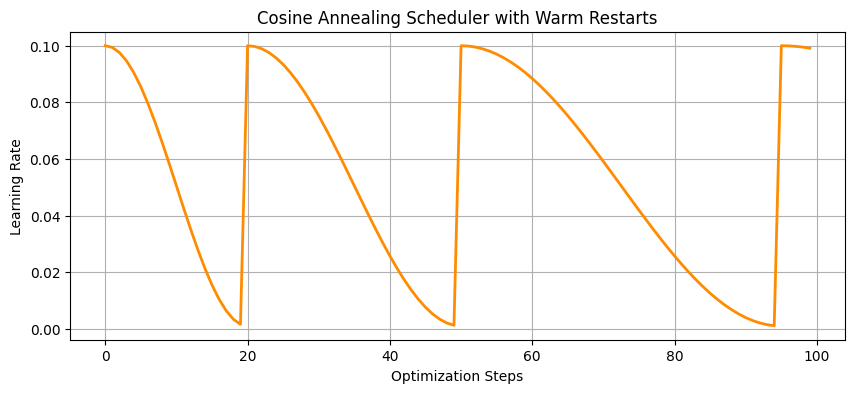

In [10]:
import math
import numpy as np
import matplotlib.pyplot as plt

class CosineAnnealingScheduler:
    def __init__(self, lr_max, lr_min, t_max, mult_factor=1):
        self.lr_max = lr_max
        self.lr_min = lr_min
        self.t_max = t_max
        self.mult_factor = mult_factor
        self.t_cur = 0

    def step(self):
        lr = self.lr_min + 0.5 * (self.lr_max - self.lr_min) * (1 + math.cos(math.pi * self.t_cur / self.t_max))
        self.t_cur += 1
        if self.t_cur >= self.t_max:
            self.t_cur = 0
            self.t_max = int(self.t_max * self.mult_factor)
        return lr

scheduler = CosineAnnealingScheduler(lr_max=0.1, lr_min=0.001, t_max=20, mult_factor=1.5)
learning_rates = [scheduler.step() for _ in range(100)]

plt.figure(figsize=(10, 4))
plt.plot(learning_rates, color='darkorange', linewidth=2)
plt.title('Cosine Annealing Scheduler with Warm Restarts')
plt.xlabel('Optimization Steps')
plt.ylabel('Learning Rate')
plt.grid(True)
plt.show()